# Análise exploratória e pré-processamento — *dataset* Titanic

**Integrantes:** 
 
Diogo Galrão Carvalho.

Felipe Artur Macedo Lima.  

Luan Cavalcante Dias Rodrigues.


**Objetivo:** conhecer a estrutura do *dataset* Titanic, classificar as variáveis, identificar valores ausentes e inconsistências e preparar os dados para as análises seguintes.

**Fonte:** Kaggle — [`yasserh/titanic-dataset`](https://www.kaggle.com/datasets/yasserh/titanic-dataset), 891 passageiros e 12 colunas.

## Carregamento dos dados

O *dataset* é baixado com `kagglehub`. O token do Kaggle **não fica gravado no notebook**: ele é lido de uma variável de ambiente ou digitado na hora.

In [1]:
import os
import kagglehub

if "KAGGLE_API_TOKEN" not in os.environ:
    from getpass import getpass
    os.environ["KAGGLE_API_TOKEN"] = getpass("Cole seu token do Kaggle: ")

os.environ.pop("KAGGLE_USERNAME", None)
os.environ.pop("KAGGLE_KEY", None)

path = kagglehub.dataset_download("yasserh/titanic-dataset")
print("Path to dataset file:", path)

Path to dataset file: /home/luanzra/.cache/kagglehub/datasets/yasserh/titanic-dataset/versions/1


In [2]:
os.listdir(path)

['Titanic-Dataset.csv']

In [3]:
import pandas as pd

df = pd.read_csv(os.path.join(path, "Titanic-Dataset.csv"))

## Bloco A — Conhecendo o dataset

### Passo 1 — Primeira olhada: `.head()`, `.info()` e `.describe()`

Antes de qualquer análise, três perguntas: **como os dados chegam** (`head`), **qual o tipo de cada coluna e quantos valores existem** (`info`) e **qual o tamanho do dataset** (`shape`). O `.describe()` aparece no Passo 3, aplicado só às variáveis quantitativas.

In [4]:
# Primeiras linhas: como os dados chegam "crus"
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
# Estrutura: tipo de cada coluna, quantos não nulos e uso de memória
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
# Tamanho do dataset
linhas, colunas = df.shape
print(f"Tamanho do dataset:\nLinhas: {linhas}\nColunas: {colunas}")

Tamanho do dataset:
Linhas: 891
Colunas: 12


#### Tabela-resumo por coluna

Junta numa só tabela o que o `.info()` e outros comandos mostrariam separados: tipo, quantidade e percentual de nulos, número de valores únicos e um exemplo de valor. Ordenada pelo percentual de nulos, para os problemas aparecerem primeiro.

In [7]:
resumo = pd.DataFrame({
    "tipo": df.dtypes,
    "nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(1),
    "valores únicos": df.nunique(),
    "exemplo": df.loc[0],
})

resumo.sort_values("% nulos", ascending=False)

,tipo,nulos,% nulos,valores únicos,exemplo
Cabin,str,687,77.1,147,NaN
Age,float64,177,19.9,88,22.0
Embarked,str,2,0.2,3,S
PassengerId,int64,0,0.0,891,1
Name,str,0,0.0,891,"Braund, Mr. Owen Harris"
Pclass,int64,0,0.0,3,3
Survived,int64,0,0.0,2,0
Sex,str,0,0.0,2,male
Parch,int64,0,0.0,7,0
SibSp,int64,0,0.0,7,1


**O que a tabela mostra:**
- **Valores ausentes** em apenas três colunas: `Cabin` (77,1%), `Age` (19,9%) e `Embarked` (2 linhas, 0,2%). O tratamento de cada uma será decidido no Passo 7.
- **Valores únicos** ajudam a classificar: `PassengerId` e `Name` têm 891 valores (um por pessoa, ou seja, são identificadores), e `Ticket` e `Cabin` têm muitos valores diferentes (alta cardinalidade).
- O **tipo do pandas** (`int64`, `float64`, `str`) não basta para classificar. `Survived` e `Pclass` são `int64`, mas os números são rótulos. A classificação correta vem no Passo 2.

### Passo 2 — Classificação das variáveis

**Critério usado:** uma variável é **quantitativa** quando o número mede ou conta algo, ou seja, somar e tirar média produz um resultado com sentido. É **qualitativa** quando o valor é um rótulo, mesmo que esteja escrito como número.

As listas abaixo guardam a classificação no código, e todas as células seguintes usam essas listas. A conferência no final garante que nenhuma das 12 colunas ficou de fora.

In [8]:
# Separar colunas por papel e por subtipo
alvo = "Survived"                                  # qualitativa nominal binária

# Fora da análise direta (rótulos únicos ou quase únicos)
ids = ["PassengerId", "Name", "Ticket", "Cabin"]

# Qualitativas
qualitativas_nominais = ["Sex", "Embarked"]
qualitativas_ordinais = ["Pclass"]

# Quantitativas
quantitativas_discretas = ["SibSp", "Parch"]
quantitativas_continuas = ["Age", "Fare"]

# Atalhos usados nas próximas células
categoricas = qualitativas_nominais + qualitativas_ordinais
numericas = quantitativas_continuas + quantitativas_discretas

# Conferência: nenhuma coluna pode ficar de fora nem aparecer duas vezes
classificadas = [alvo] + ids + categoricas + numericas
assert sorted(classificadas) == sorted(df.columns), set(df.columns) ^ set(classificadas)

print(f"Alvo: {alvo}")
print(f"Identificadores (fora da análise direta): {ids}")
print(f"Qualitativas nominais: {qualitativas_nominais}")
print(f"Qualitativas ordinais: {qualitativas_ordinais}")
print(f"Quantitativas discretas: {quantitativas_discretas}")
print(f"Quantitativas contínuas: {quantitativas_continuas}")
print(f"Total classificado: {len(classificadas)} de {df.shape[1]} colunas")

Alvo: Survived
Identificadores (fora da análise direta): ['PassengerId', 'Name', 'Ticket', 'Cabin']
Qualitativas nominais: ['Sex', 'Embarked']
Qualitativas ordinais: ['Pclass']
Quantitativas discretas: ['SibSp', 'Parch']
Quantitativas contínuas: ['Age', 'Fare']
Total classificado: 12 de 12 colunas


#### Tabela de classificação

**Critério usado:** uma variável é **quantitativa** quando o número mede ou conta algo, ou seja, somar e tirar média produz um resultado com sentido. É **qualitativa** quando o valor é um rótulo, mesmo que esteja escrito como número.

| Coluna | Tipo | Subtipo | Justificativa | Papel na análise |
|---|---|---|---|---|
| `Survived` | Qualitativa | Nominal (binária) | 0/1 é um código para "não sobreviveu/sobreviveu". Não existe "meia sobrevivência". A média (0,38) só tem leitura porque, numa variável 0/1, ela vira a **proporção** de sobreviventes. | **Variável alvo** |
| `Pclass` | Qualitativa | **Ordinal** | Há ordem (1ª > 2ª > 3ª classe), mas a distância entre as classes não é medida. A 1ª não vale "três vezes" a 3ª, e a média 2,3 não significa nada. | Explicativa (indicador socioeconômico) |
| `Sex` | Qualitativa | Nominal (binária) | Duas categorias sem ordem. | Explicativa |
| `Embarked` | Qualitativa | Nominal | Porto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton), sem ordem. 2 ausentes. | Explicativa |
| `Age` | Quantitativa | Contínua | Idade em anos, uma medida que admite frações (0,42 = cerca de 5 meses). 19,9% ausentes. | Explicativa |
| `Fare` | Quantitativa | Contínua | Valor monetário (libras) com casas decimais. **Atenção:** é o preço do bilhete, não por pessoa (ver inconsistências). | Explicativa |
| `SibSp` | Quantitativa | **Discreta** | **Contagem** de irmãos e cônjuges a bordo (0, 1, 2…). Só aceita inteiros, e a soma e a média fazem sentido. | Explicativa (tamanho da família) |
| `Parch` | Quantitativa | **Discreta** | **Contagem** de pais e filhos a bordo. Mesmo raciocínio de `SibSp`. | Explicativa (tamanho da família) |
| `PassengerId` | Qualitativa | Nominal (identificador) | Número sequencial que só identifica a linha (891 valores únicos). Somar ids não faz sentido. | Descartar |
| `Name` | Qualitativa | Nominal (texto livre) | Único por pessoa. | Descartar (o título, como Mr/Mrs/Master, pode ser extraído depois) |
| `Ticket` | Qualitativa | Nominal (alta cardinalidade) | 681 códigos para 891 pessoas, com prefixos irregulares. | Descartar como variável, mas serve para contar **quantas pessoas dividem o bilhete** |
| `Cabin` | Qualitativa | Nominal (alta cardinalidade) | 147 códigos e **77,1% ausentes**. Algumas linhas listam várias cabines ("C23 C25 C27"). | Descartar ou derivar o **deck** (letra) e um indicador "tem cabine registrada" |

**Por que separar assim importa para o resto da análise:**
- **Qualitativas** (nominais e ordinais) são resumidas por **contagem e proporção** e vão para gráficos de barras. Na codificação (Passo 9), as **nominais** recebem *one-hot*, porque não têm ordem. A **ordinal** `Pclass` pode manter os códigos 1, 2 e 3, já que a ordem é real.
- **Quantitativas** são resumidas por média, mediana, desvio padrão e quartis e vão para histogramas e boxplots. A análise de *outliers* (Passo 8) e a normalização (Passo 10) só se aplicam a elas, principalmente às **contínuas**.
- `SibSp` e `Parch` são **quantitativas discretas**: entram no `describe()` e na análise de outliers. Como têm poucos valores distintos, também podem ser **exibidas** como barras, mas isso é uma escolha de gráfico, não muda a classificação.
- `Survived` está em 0/1 por conveniência de código. Ela é tratada como categoria (a taxa de sobrevivência é uma proporção) e nunca é normalizada.

### Passo 3 — Estatísticas descritivas das variáveis quantitativas

O `.describe()` é aplicado **só às quantitativas** (contínuas e discretas). Para as qualitativas, média e desvio padrão não têm sentido, e o resumo adequado é a contagem de cada categoria, feita logo depois. Na tabela, a coluna **50% é a mediana**.

In [9]:
df[numericas].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00


**Leitura:**
- **`Age`:** média (29,7) e mediana (28) próximas, o que indica distribuição **pouco assimétrica**. Vai de bebês (0,42) a 80 anos, e metade dos passageiros tem entre 20 e 38 anos.
- **`Fare`:** média (32,2) é mais que o **dobro da mediana** (14,45), com desvio padrão (49,7) maior que a própria média e máximo de 512. Esses números indicam **forte assimetria à direita**: a maioria pagou pouco, e poucos valores muito altos puxam a média. É a principal candidata a *outliers* (Passo 8).
- **`SibSp` e `Parch`:** a mediana é 0 nas duas, então **a maioria viajou sem irmãos/cônjuge e sem pais/filhos**. Os máximos (8 e 6) são famílias grandes, raras mas reais.

#### Frequência das categorias e checagens de qualidade

Para as qualitativas, o resumo é a **contagem por categoria**. `SibSp` e `Parch` entram aqui também porque têm poucos valores distintos.

In [10]:
for col in categoricas + quantitativas_discretas:
    print(f"\n---{col}---")
    print(df[col].value_counts(dropna=False).sort_index())


---Sex---
Sex
female    314
male      577
Name: count, dtype: int64

---Embarked---
Embarked
C      168
Q       77
S      644
NaN      2
Name: count, dtype: int64

---Pclass---
Pclass
1    216
2    184
3    491
Name: count, dtype: int64

---SibSp---
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

---Parch---
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64


In [11]:
# Checagens de qualidade
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"Taxa de sobrevivência: {df[alvo].mean():.1%}")

Linhas duplicadas: 0
Taxa de sobrevivência: 38.4%


**Leitura:**
- As categorias são **desiguais**: 55% dos passageiros estavam na 3ª classe (491 de 891), 65% eram homens (577) e 72% embarcaram em Southampton (644). Grupos pequenos, como Queenstown (77), terão taxas de sobrevivência menos estáveis nas comparações.
- **Nenhuma linha duplicada**, então não é preciso remover registros repetidos.
- **Taxa de sobrevivência de 38,4%:** a variável alvo é **desbalanceada** (cerca de 6 mortos para cada 4 sobreviventes). Isso será analisado nos Passos 4 e 6.

### Passo 2 (cont.) — Inconsistências iniciais

Três valores nos próprios resultados acima pedem verificação antes de seguir: `Fare` mínima = 0, `Ticket` com menos valores únicos que passageiros e `Age` mínima = 0,42.

#### 1) Tarifa zero: faz sentido pagar 0 por uma passagem?

In [12]:
tarifa_zero = df[df["Fare"] == 0]
print(f"Passageiros com Fare = 0: {len(tarifa_zero)} ({len(tarifa_zero)/len(df):.1%})")
print(tarifa_zero["Sex"].value_counts().to_dict(), "| Embarque:", tarifa_zero["Embarked"].value_counts().to_dict())
print(f"Sobreviveram: {tarifa_zero['Survived'].sum()} de {len(tarifa_zero)}")
tarifa_zero[["Name", "Pclass", "Ticket", "Age", "Survived"]].sort_values("Ticket")

Passageiros com Fare = 0: 15 (1.7%)
{'male': 15} | Embarque: {'S': 15}
Sobreviveram: 1 de 15


,Name,Pclass,Ticket,Age,Survived
806,"Andrews, Mr. Thomas Jr",1,112050,39.0,0
633,"Parr, Mr. William Henry Marsh",1,112052,NaN,0
815,"Fry, Mr. Richard",1,112058,NaN,0
263,"Harrison, Mr. William",1,112059,40.0,0
822,"Reuchlin, Jonkheer. John George",1,19972,38.0,0
277,"Parkes, Mr. Francis ""Frank""",2,239853,NaN,0
413,"Cunningham, Mr. Alfred Fleming",2,239853,NaN,0
466,"Campbell, Mr. William",2,239853,NaN,0
481,"Frost, Mr. Anthony Wood ""Archie""",2,239854,NaN,0
732,"Knight, Mr. Robert J",2,239855,NaN,0


#### 2) Bilhetes compartilhados: `Fare` é o preço por pessoa ou por bilhete?

`Ticket` tem 681 códigos para 891 pessoas, ou seja, há bilhetes usados por mais de uma pessoa. Se a tarifa se repete igual para todos do mesmo bilhete, ela é o preço do **bilhete inteiro**.

In [13]:
# Quantas pessoas usam o mesmo bilhete (valor repetido em cada linha)
pessoas_por_ticket = df.groupby("Ticket")["Ticket"].transform("size")
compartilhados = df.loc[pessoas_por_ticket > 1, "Ticket"].nunique()
print(f"Bilhetes usados por mais de uma pessoa: {compartilhados}")
print(f"Passageiros nesses bilhetes: {(pessoas_por_ticket > 1).sum()} ({(pessoas_por_ticket > 1).mean():.1%})")

# A Fare se repete dentro do mesmo bilhete?
fares_por_ticket = df.groupby("Ticket")["Fare"].nunique()
print(f"Bilhetes compartilhados com Fare diferente entre as pessoas: {(fares_por_ticket > 1).sum()}")

# Exemplos: a maior tarifa do dataset e a família Sage
print("\nMaior tarifa do dataset:")
display(df.loc[df["Fare"] == df["Fare"].max(), ["Name", "Ticket", "Pclass", "Fare"]])
print("Família Sage (mesmo bilhete):")
display(df.loc[df["Ticket"] == "CA. 2343", ["Name", "Ticket", "Pclass", "Fare"]])

Bilhetes usados por mais de uma pessoa: 134
Passageiros nesses bilhetes: 344 (38.6%)
Bilhetes compartilhados com Fare diferente entre as pessoas: 1

Maior tarifa do dataset:


,Name,Ticket,Pclass,Fare
258,"Ward, Miss. Anna",PC 17755,1,512.3292
679,"Cardeza, Mr. Thomas Drake Martinez",PC 17755,1,512.3292
737,"Lesurer, Mr. Gustave J",PC 17755,1,512.3292


Família Sage (mesmo bilhete):


,Name,Ticket,Pclass,Fare
159,"Sage, Master. Thomas Henry",CA. 2343,3,69.55
180,"Sage, Miss. Constance Gladys",CA. 2343,3,69.55
201,"Sage, Mr. Frederick",CA. 2343,3,69.55
324,"Sage, Mr. George John Jr",CA. 2343,3,69.55
792,"Sage, Miss. Stella Anna",CA. 2343,3,69.55
846,"Sage, Mr. Douglas Bullen",CA. 2343,3,69.55
863,"Sage, Miss. Dorothy Edith ""Dolly""",CA. 2343,3,69.55


In [14]:
# Quanto muda se dividirmos a tarifa pelo número de pessoas no bilhete?
comparacao = pd.DataFrame({
    "Fare (por bilhete)": df["Fare"],
    "Fare por pessoa (estimada)": df["Fare"] / pessoas_por_ticket,
}).describe().T.round(2)

comparacao

,count,mean,std,min,25%,50%,75%,max
Fare (por bilhete),891.0,32.20,49.69,0.0,7.91,14.45,31.00,512.33
Fare por pessoa (estimada),891.0,17.79,21.22,0.0,7.76,8.85,24.29,221.78


#### 3) Idades fracionárias: erro de digitação ou dado real?

In [15]:
bebes = df[df["Age"] < 1]
print(f"Passageiros com menos de 1 ano: {len(bebes)} | sobreviveram: {bebes['Survived'].sum()}")
display(bebes[["Name", "Age", "Pclass", "Survived"]])

# Idades acima de 1 ano terminadas em .5 (no dicionário do dataset, indicam idade ESTIMADA)
estimadas = df[(df["Age"] > 1) & (df["Age"] % 1 == 0.5)]
print(f"Idades estimadas (xx.5): {len(estimadas)}")

Passageiros com menos de 1 ano: 7 | sobreviveram: 7


,Name,Age,Pclass,Survived
78,"Caldwell, Master. Alden Gates",0.83,2,1
305,"Allison, Master. Hudson Trevor",0.92,1,1
469,"Baclini, Miss. Helene Barbara",0.75,3,1
644,"Baclini, Miss. Eugenie",0.75,3,1
755,"Hamalainen, Master. Viljo",0.67,2,1
803,"Thomas, Master. Assad Alexander",0.42,3,1
831,"Richards, Master. George Sibley",0.83,2,1


Idades estimadas (xx.5): 18


#### Leitura das inconsistências

1. **`Fare` = 0 (15 passageiros, 1,7%).** Em princípio ninguém paga zero por uma passagem, então o valor merece checagem. O padrão, porém, não é aleatório: são **todos homens, todos embarcados em Southampton**, distribuídos pelas três classes, e vários têm bilhetes em sequência (`LINE`, `2398xx`, `1120xx`). Isso indica **passagens de cortesia** (funcionários ou convidados das empresas envolvidas, por exemplo Thomas Andrews, projetista do navio), não erro de digitação. **Decisão:** manter as linhas e registrar o motivo. Não serão tratadas como ausentes nem removidas como outliers, mas vale lembrar delas ao interpretar `Fare` (puxam o mínimo e a média para baixo).

2. **`Ticket` com 681 valores para 891 pessoas.** São **134 bilhetes compartilhados por 344 passageiros (38,6%)**, e em 133 deles a `Fare` é **idêntica para todos do grupo**. Conclusão: **`Fare` é o preço do bilhete inteiro, não por pessoa**. Exemplos: a família Sage (7 pessoas, 3ª classe) aparece com 69,55 cada, e o máximo de 512,33 é **um único bilhete para 3 pessoas**. **Impacto na análise de outliers (Passo 8):** parte dos valores altos de `Fare` não representa pessoas que pagaram caro, e sim **grupos**. Dividindo pelo tamanho do grupo, a média cai de 32,2 para cerca de 17,8 e o máximo de 512 para cerca de 222. *Limitação:* o dataset tem só 891 dos passageiros do navio, então o tamanho do grupo pode estar subestimado. Uma `Fare` por pessoa é candidata a variável derivada, e a decisão fica para o Passo 8.

3. **`Age` mínima = 0,42.** Não é erro: são **7 bebês com menos de 1 ano** (0,42 ano ≈ 5 meses), todos com título *Master/Miss*, coerentes com crianças, e **todos sobreviveram**. A idade fracionária representa meses. Há ainda **18 idades terminadas em .5** acima de 1 ano, que segundo a documentação do dataset são **idades estimadas**. Isso não invalida o dado, mas mostra que parte de `Age` é aproximada, além dos 19,9% ausentes.

### Resumo do Bloco A — o que levar para os próximos passos

| Achado | Onde será tratado |
|---|---|
| Ausentes: `Cabin` 77,1%, `Age` 19,9%, `Embarked` 2 linhas | Passo 7 (valores ausentes) |
| `Fare` é **por bilhete**, com forte assimetria à direita; 15 tarifas zero são cortesias, não erro | Passo 8 (*outliers*): avaliar `Fare` por pessoa |
| `SibSp`/`Parch` têm máximos altos (8 e 6), mas são famílias reais | Passo 8 (*outliers*) |
| `PassengerId`, `Name`, `Ticket`, `Cabin` são identificadores ou de alta cardinalidade | Passo 8 (redução de colunas), com possível extração de título e deck |
| `Sex` e `Embarked` são nominais; `Pclass` é ordinal | Passo 9 (codificação) |
| `Age` e `Fare` são contínuas, em escalas muito diferentes | Passo 10 (normalização/padronização) |
| Alvo desbalanceado (38,4% sobreviventes) | Passos 4 e 6 |
| Nenhuma linha duplicada | Nenhuma ação necessária |

## Bloco B — Variável alvo e relações entre variáveis

Este bloco responde a uma pergunta central: **quem sobreviveu, e o que diferencia esses passageiros dos demais?** Primeiro a distribuição do alvo (Passo 4), depois a comparação por categoria (Passo 5) e por fim combinações de duas ou mais variáveis, terminando no mapa de calor de correlação (Passo 6).

**Padrão visual usado em todos os gráficos:** cada cor tem sempre o mesmo significado. Laranja = não sobreviveu, azul = sobreviveu (taxa de sobrevivência), verde = mulheres, roxo = homens. As classes usam tons de cinza do escuro (1ª) ao claro (3ª), porque são uma escala ordenada. A linha tracejada marca a **taxa geral de sobrevivência (38,4%)**, que serve de referência para dizer se um grupo está acima ou abaixo da média.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12,
    "grid.color": "#e6e5e0", "axes.edgecolor": "#8a8985",
})

# Cores fixas por significado (a mesma cor representa sempre o mesmo grupo)
PALETA_ALVO = {0: "#eb6834", 1: "#2a78d6"}          # laranja = não sobreviveu | azul = sobreviveu
COR_TAXA = "#2a78d6"                                 # barras de taxa de sobrevivência
PALETA_SEXO = {"female": "#1baf7a", "male": "#6250d6"}
PALETA_CLASSE = {1: "#3d3d3a", 2: "#8a8985", 3: "#c9c8c2"}  # escala ordenada: escuro = 1ª classe

# Rótulos em português para os gráficos
ROTULOS = {
    "Survived": {0: "Não sobreviveu", 1: "Sobreviveu"},
    "Sex": {"female": "Mulher", "male": "Homem"},
    "Pclass": {1: "1ª classe", 2: "2ª classe", 3: "3ª classe"},
    "Embarked": {"C": "Cherbourg", "Q": "Queenstown", "S": "Southampton"},
}
NOMES = {"Sex": "Sexo", "Pclass": "Classe", "Embarked": "Porto de embarque"}

taxa_geral = df[alvo].mean()


def rotular_barras(ax, formato="{:.0%}"):
    """Escreve o valor em cima de cada barra (sem rótulo em barra vazia)."""
    for barras in ax.containers:
        ax.bar_label(barras, labels=[formato.format(v) if v == v else "" for v in barras.datavalues],
                     padding=2, fontsize=9, color="#3d3d3a")


def linha_media(ax):
    """Linha de referência com a taxa geral de sobrevivência."""
    ax.axhline(taxa_geral, ls="--", lw=1.2, color="#52514e")
    ax.text(ax.get_xlim()[1], taxa_geral, f" média geral\n {taxa_geral:.1%}", va="center", fontsize=8, color="#52514e")


def legenda(ax, mapa, titulo=None, **kw):
    """Troca os códigos da legenda (0/1, female/male) pelos rótulos em português."""
    handles, labels = ax.get_legend_handles_labels()
    traducao = {str(k): v for k, v in mapa.items()}
    ax.legend(handles, [traducao.get(l, l) for l in labels], title=titulo, frameon=False, **kw)

### Passo 4 — Distribuição da variável alvo (Survived)

In [17]:
contagem = df[alvo].value_counts().sort_index()
percentual = df[alvo].value_counts(normalize=True).sort_index()

tabela_alvo = pd.DataFrame({"Passageiros": contagem, "%": (percentual * 100).round(1)})
tabela_alvo.index = tabela_alvo.index.map(ROTULOS["Survived"])
tabela_alvo.index.name = "Survived"
tabela_alvo

,Passageiros,%
Survived,,
Não sobreviveu,549,61.6
Sobreviveu,342,38.4


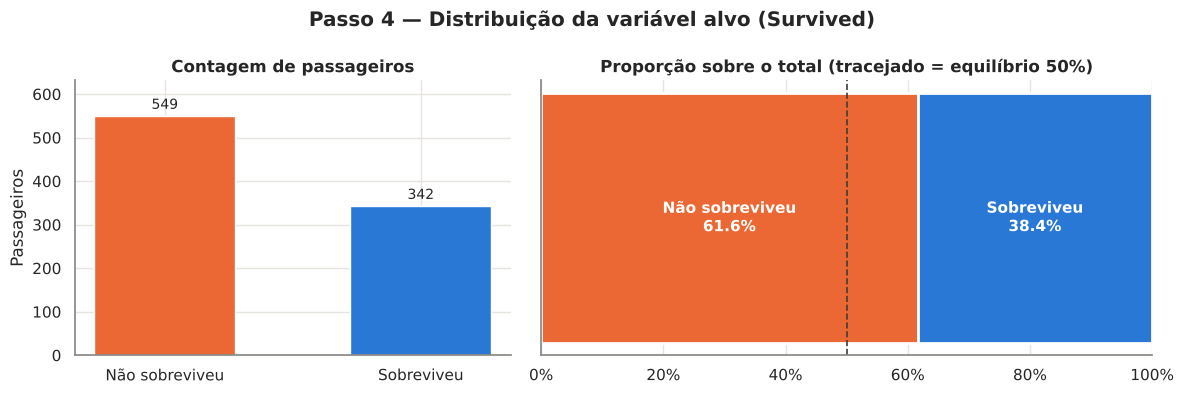

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.4]})

# Gráfico 1: contagem absoluta
nomes = [ROTULOS["Survived"][k] for k in contagem.index]
ax1.bar(nomes, contagem.values, color=[PALETA_ALVO[k] for k in contagem.index], width=0.55)
ax1.bar_label(ax1.containers[0], padding=3, fontsize=10)
ax1.set_title("Contagem de passageiros")
ax1.set_ylabel("Passageiros")
ax1.set_ylim(0, contagem.max() * 1.15)

# Gráfico 2: proporção em barra 100% (comparada com o equilíbrio 50/50)
inicio = 0
for k in percentual.index:
    ax2.barh([""], percentual[k], left=inicio, color=PALETA_ALVO[k], edgecolor="white", linewidth=2, height=0.5)
    ax2.text(inicio + percentual[k] / 2, 0, f"{ROTULOS['Survived'][k]}\n{percentual[k]:.1%}",
             ha="center", va="center", color="white", fontweight="bold", fontsize=11)
    inicio += percentual[k]
ax2.axvline(0.5, ls="--", lw=1.2, color="#3d3d3a")
ax2.set_xlim(0, 1)
ax2.xaxis.set_major_formatter(PercentFormatter(1))
ax2.set_title("Proporção sobre o total (tracejado = equilíbrio 50%)")
ax2.grid(axis="y", visible=False)

fig.suptitle("Passo 4 — Distribuição da variável alvo (Survived)", fontweight="bold")
plt.tight_layout()
plt.show()

**Leitura e impacto do desbalanceamento:**
- De 891 passageiros, **549 não sobreviveram (61,6%)** e **342 sobreviveram (38,4%)**, cerca de 1,6 mortos para cada sobrevivente.
- É um **desbalanceamento moderado**: a classe minoritária ainda tem centenas de exemplos, então não é um caso extremo (como fraude, com menos de 1%), mas precisa ser levado em conta.
- **Impacto prático:** um modelo que chutasse "não sobreviveu" para todo mundo acertaria **61,6%** sem aprender nada. Por isso:
  - a **acurácia sozinha engana**; ao modelar, comparar com esse piso de 61,6% e usar também precisão, *recall* e F1 da classe "sobreviveu";
  - a divisão treino/teste deve ser **estratificada** (`stratify=y`), mantendo os mesmos 61,6/38,4 nos dois conjuntos;
  - **nas comparações deste bloco** usamos a **taxa de sobrevivência (%) de cada grupo**, e não a contagem, porque a contagem de mortos é maior em quase todos os grupos só porque eles são maioria.

### Passo 5 — Sobrevivência por categoria (barras agrupadas)

Linha de cima: **barras agrupadas** com a contagem de não sobreviventes e sobreviventes em cada categoria. Linha de baixo: a **taxa de sobrevivência** de cada categoria, que permite comparar grupos de tamanhos diferentes. O `n` abaixo de cada categoria é o número de passageiros.

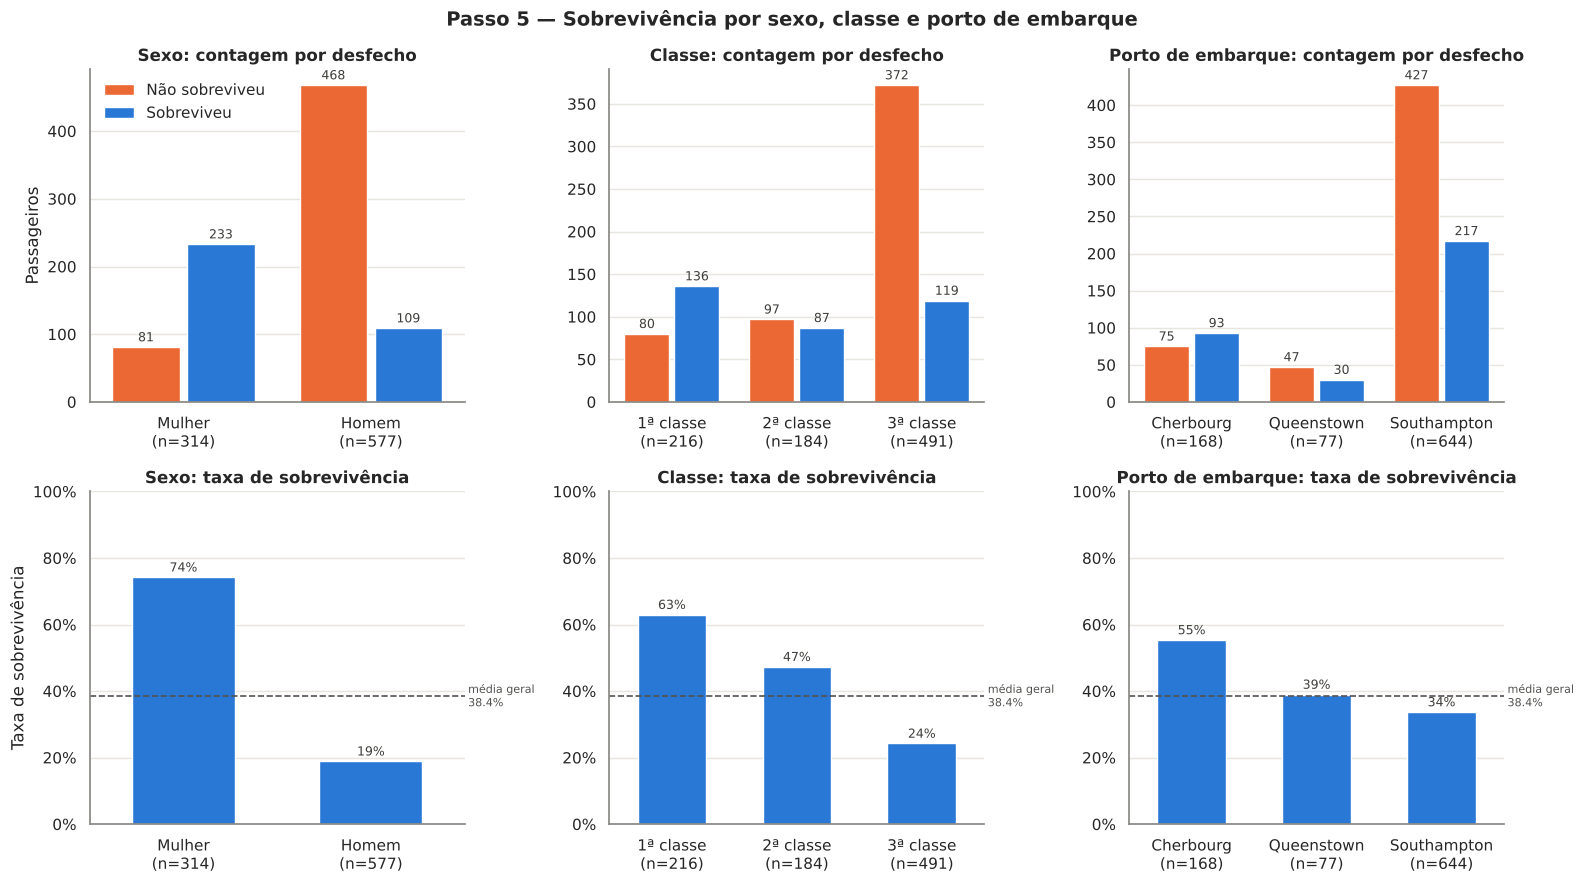

In [19]:
colunas_passo5 = ["Sex", "Pclass", "Embarked"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for j, col in enumerate(colunas_passo5):
    ordem = sorted(df[col].dropna().unique())
    n = df[col].value_counts()
    rotulos_x = [f"{ROTULOS[col][v]}\n(n={n[v]})" for v in ordem]

    # Linha 1: barras agrupadas (contagem por Survived)
    ax = axes[0, j]
    sns.countplot(data=df, x=col, hue=alvo, order=ordem, palette=PALETA_ALVO, saturation=1, ax=ax, gap=0.1)
    rotular_barras(ax, "{:.0f}")
    ax.set_xticks(range(len(ordem)), rotulos_x)
    ax.set_title(f"{NOMES[col]}: contagem por desfecho")
    ax.set_xlabel("")
    ax.set_ylabel("Passageiros" if j == 0 else "")
    if j == 0:
        legenda(ax, ROTULOS["Survived"], loc="upper left")
    else:
        ax.get_legend().remove()

    # Linha 2: taxa de sobrevivência
    ax = axes[1, j]
    sns.barplot(data=df, x=col, y=alvo, order=ordem, errorbar=None, color=COR_TAXA, saturation=1, width=0.55, ax=ax)
    rotular_barras(ax)
    ax.set_xticks(range(len(ordem)), rotulos_x)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(f"{NOMES[col]}: taxa de sobrevivência")
    ax.set_xlabel("")
    ax.set_ylabel("Taxa de sobrevivência" if j == 0 else "")
    linha_media(ax)

fig.suptitle("Passo 5 — Sobrevivência por sexo, classe e porto de embarque", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

**Leitura:**
- **Sexo é o fator mais forte:** **74,2%** das mulheres sobreviveram, contra **18,9%** dos homens, quase 4 vezes mais. Os homens são maioria (577), mas a maior parte dos sobreviventes é de mulheres (233 de 342). Isso é coerente com o protocolo "mulheres e crianças primeiro".
- **A classe tem um gradiente claro:** 1ª classe **63,0%**, 2ª **47,3%** e 3ª **24,2%**. Quanto melhor a classe, maior a chance, o que confirma `Pclass` como ordinal e como indicador socioeconômico (e provavelmente de proximidade dos botes, já que as cabines de 1ª ficavam nos conveses superiores).
- **Porto de embarque:** Cherbourg tem **55,4%**, acima de Queenstown (**39,0%**) e Southampton (**33,7%**). Ao contrário de sexo e classe, **não há motivo direto** para o porto mudar a chance de sobreviver. Essa diferença é investigada no Passo 6.3.

### Passo 6 — Balanceamento por categoria e combinações de variáveis

#### 6.1 Balanceamento de cada variável categórica em relação a `Survived`

Para cada categoria: quantos passageiros ela tem (o grupo é grande ou pequeno?) e como se dividem entre os dois desfechos.

In [20]:
partes = []
for col in categoricas:
    t = pd.crosstab(df[col], df[alvo])
    t.columns = ["Não sobreviveu", "Sobreviveu"]
    t["Total"] = t.sum(axis=1)
    t["% do dataset"] = (t["Total"] / len(df) * 100).round(1)
    t["Taxa de sobrevivência (%)"] = (t["Sobreviveu"] / t["Total"] * 100).round(1)
    t.index = pd.MultiIndex.from_tuples([(NOMES[col], ROTULOS[col][v]) for v in t.index],
                                        names=["Variável", "Categoria"])
    partes.append(t)

balanceamento = pd.concat(partes)
balanceamento

Não sobreviveu  Sobreviveu  Total  \
Variável          Categoria                                        
Sexo              Mulher                   81         233    314   
                  Homem                   468         109    577   
Porto de embarque Cherbourg                75          93    168   
                  Queenstown               47          30     77   
                  Southampton             427         217    644   
Classe            1ª classe                80         136    216   
                  2ª classe                97          87    184   
                  3ª classe               372         119    491   

                               % do dataset  Taxa de sobrevivência (%)  
Variável          Categoria                                             
Sexo              Mulher               35.2                       74.2  
                  Homem                64.8                       18.9  
Porto de embarque Cherbourg            18.9                       55.4  
                  Queenstown            8.6                       39.0  
                  Southampton          72.3                       33.7  
Classe            1ª classe            24.2                       63.0  
                  2ª classe            20.7                       47.3  
                  3ª classe            55.1                       24.2

**Leitura:**
- **As categorias são desbalanceadas entre si:** 3ª classe (55,1%), homens (64,8%) e Southampton (72,3%) concentram a maior parte dos passageiros. Em compensação, Queenstown tem só 77 pessoas (8,6%), então a taxa desse grupo é **menos confiável**: poucas pessoas a mais ou a menos mudam bastante o percentual.
- **O desbalanceamento do alvo muda conforme o grupo:** entre as **mulheres**, a maioria **sobreviveu** (74,2%), o contrário do dataset como um todo. Entre os **homens** e na **3ª classe**, o desequilíbrio é bem mais forte que a média (81,1% e 75,8% de mortos). Ou seja, o alvo não é "uniformemente desbalanceado": ele depende do perfil do passageiro, e é isso que torna essas variáveis úteis para prever a sobrevivência.

#### 6.2 Sexo × Classe × Sobrevivência (multivariado)

Sexo e classe foram os fatores mais fortes no Passo 5. A pergunta aqui é se o efeito de um **depende** do outro.

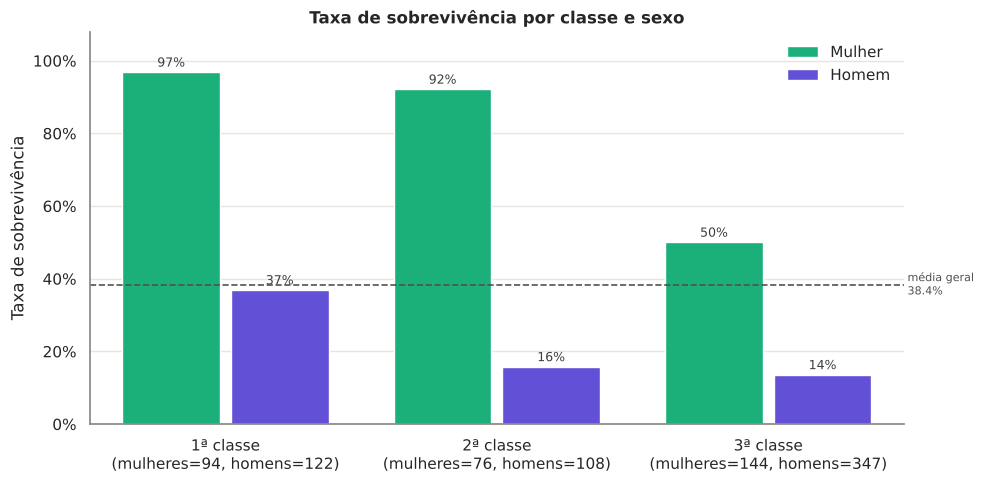

Sex,Mulher,Homem
Pclass,,
1ª classe,96.8,36.9
2ª classe,92.1,15.7
3ª classe,50.0,13.5


In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=df, x="Pclass", y=alvo, hue="Sex", hue_order=["female", "male"], palette=PALETA_SEXO,
            errorbar=None, saturation=1, gap=0.1, ax=ax)
rotular_barras(ax)

n = pd.crosstab(df["Pclass"], df["Sex"])
ax.set_xticks(range(3), [f"{ROTULOS['Pclass'][c]}\n(mulheres={n.loc[c, 'female']}, homens={n.loc[c, 'male']})" for c in n.index])
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("")
ax.set_ylabel("Taxa de sobrevivência")
ax.set_title("Taxa de sobrevivência por classe e sexo")
legenda(ax, ROTULOS["Sex"], loc="upper right")
linha_media(ax)
plt.tight_layout()
plt.show()

# Mesma informação em tabela (%)
(pd.crosstab(df["Pclass"], df["Sex"], values=df[alvo], aggfunc="mean") * 100).round(1) \
    .rename(index=ROTULOS["Pclass"], columns=ROTULOS["Sex"])

**Leitura:**
- **Mulheres de 1ª e 2ª classe quase todas sobreviveram** (96,8% e 92,1%). Na **3ª classe**, a taxa das mulheres **cai para 50,0%**.
- **Homens ficam abaixo da média em todas as classes.** Mesmo na 1ª classe só 36,9% sobreviveram, e na 2ª e na 3ª a taxa fica em torno de 14 a 16%.
- **Os dois efeitos interagem:** a vantagem da classe é muito maior para as mulheres (de 50% para 97%) do que para os homens (de 14% para 37%). Um homem de 1ª classe teve **menos** chance do que uma mulher de 3ª. Conclusão: **o sexo pesa mais que a classe**, e a classe "decide" principalmente entre as mulheres. Um modelo que olhe as duas variáveis separadamente perde parte dessa informação.

#### 6.3 Porto de embarque × Classe: o porto realmente importa?

No Passo 5, Cherbourg teve a maior taxa de sobrevivência. Hipótese: a diferença vem de **quem embarcou** em cada porto, e não do porto em si.

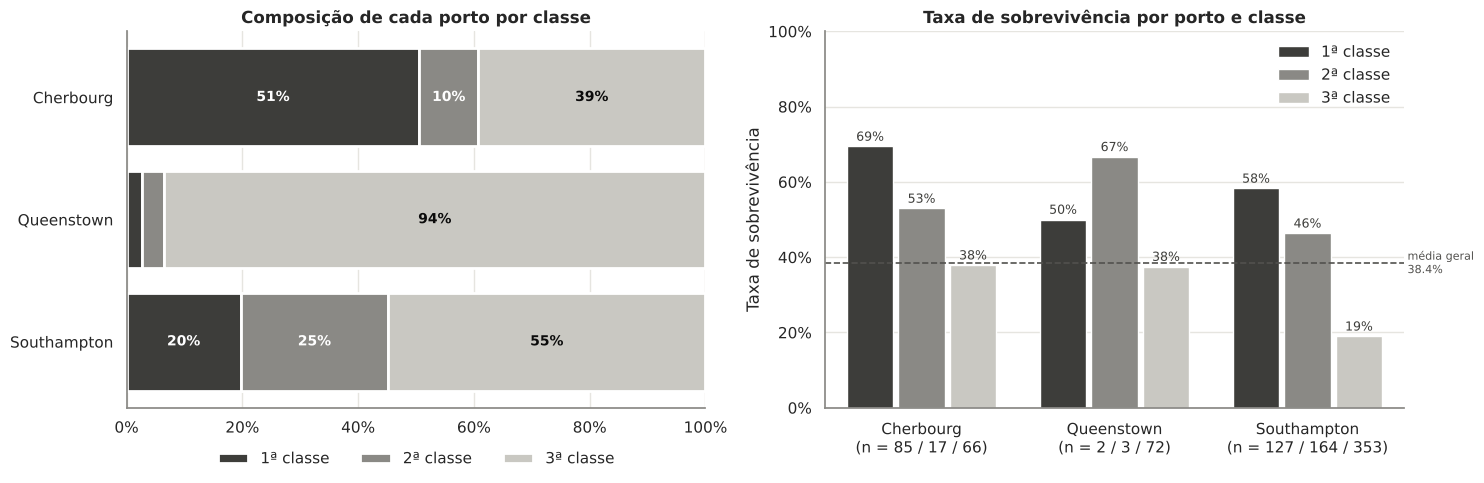

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Esquerda: composição de cada porto por classe (barras 100%)
composicao = pd.crosstab(df["Embarked"], df["Pclass"], normalize="index")
inicio = pd.Series(0.0, index=composicao.index)
for c in composicao.columns:
    ax1.barh([ROTULOS["Embarked"][p] for p in composicao.index], composicao[c], left=inicio,
             color=PALETA_CLASSE[c], edgecolor="white", linewidth=2, label=ROTULOS["Pclass"][c])
    for i, p in enumerate(composicao.index):
        if composicao.loc[p, c] >= 0.06:
            ax1.text(inicio[p] + composicao.loc[p, c] / 2, i, f"{composicao.loc[p, c]:.0%}", ha="center", va="center",
                     color="white" if c < 3 else "#0b0b0b", fontsize=10, fontweight="bold")
    inicio += composicao[c]
ax1.xaxis.set_major_formatter(PercentFormatter(1))
ax1.set_xlim(0, 1)
ax1.invert_yaxis()
ax1.set_title("Composição de cada porto por classe")
ax1.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax1.grid(axis="y", visible=False)

# Direita: taxa de sobrevivência por porto, separada por classe
sns.barplot(data=df, x="Embarked", y=alvo, hue="Pclass", order=["C", "Q", "S"], palette=PALETA_CLASSE,
            errorbar=None, saturation=1, gap=0.1, ax=ax2)
rotular_barras(ax2)
n = pd.crosstab(df["Embarked"], df["Pclass"])
ax2.set_xticks(range(3), [f"{ROTULOS['Embarked'][p]}\n(n = {n.loc[p, 1]} / {n.loc[p, 2]} / {n.loc[p, 3]})" for p in ["C", "Q", "S"]])
ax2.set_ylim(0, 1)
ax2.yaxis.set_major_formatter(PercentFormatter(1))
ax2.set_xlabel("")
ax2.set_ylabel("Taxa de sobrevivência")
ax2.set_title("Taxa de sobrevivência por porto e classe")
legenda(ax2, ROTULOS["Pclass"], loc="upper right")
linha_media(ax2)

plt.tight_layout()
plt.show()

**Leitura:**
- **Os portos têm perfis muito diferentes:** em Cherbourg, **51%** dos passageiros eram da 1ª classe. Em Queenstown, **94%** eram da 3ª classe, e Southampton fica no meio (55% na 3ª). Cherbourg também tinha proporcionalmente mais mulheres (43% contra 32% em Southampton).
- **Comparando dentro da mesma classe, a vantagem de Cherbourg diminui bastante.** Ainda sobra alguma diferença (por exemplo, 3ª classe: 37,9% em Cherbourg contra 19,0% em Southampton), mas parte dela também pode vir da composição por sexo. Em Queenstown, os grupos de 1ª e 2ª classe têm só 2 e 3 pessoas, então essas taxas **não devem ser interpretadas**.
- **Conclusão:** a maior parte do "efeito do porto" é **efeito de composição (variável de confusão)**. Cherbourg parecia "salvar mais" porque recebeu mais passageiros ricos e mais mulheres. Este é o tipo de cuidado que um gráfico de uma variável só (Passo 5) não mostra: **correlação não é causa**.

#### 6.4 Idade × Sexo × Sobrevivência: "mulheres e crianças primeiro"?

A idade foi dividida em faixas para comparar com o sexo. As faixas são criadas numa **cópia** do dataset (`eda`), para não alterar `df` antes da limpeza do Bloco C. Os 177 passageiros sem idade ficam de fora deste gráfico.

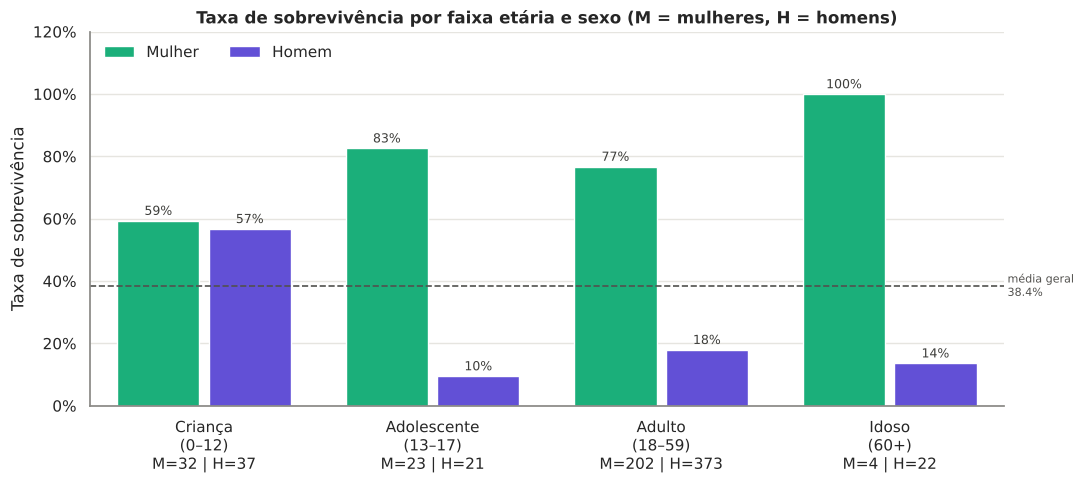

Taxa de sobrevivência por presença de idade:
Age
Com idade    40.6%
Sem idade    29.4%
Name: Survived, dtype: str


In [23]:
eda = df.copy()
eda["FaixaEtaria"] = pd.cut(eda["Age"], bins=[0, 12, 17, 59, 100],
                            labels=["Criança\n(0–12)", "Adolescente\n(13–17)", "Adulto\n(18–59)", "Idoso\n(60+)"])

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=eda, x="FaixaEtaria", y=alvo, hue="Sex", hue_order=["female", "male"], palette=PALETA_SEXO,
            errorbar=None, saturation=1, gap=0.1, ax=ax)
rotular_barras(ax)

n = pd.crosstab(eda["FaixaEtaria"], eda["Sex"])
ax.set_xticks(range(len(n)), [f"{faixa}\nM={n.loc[faixa, 'female']} | H={n.loc[faixa, 'male']}" for faixa in n.index])
ax.set_ylim(0, 1.2)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("")
ax.set_ylabel("Taxa de sobrevivência")
ax.set_title("Taxa de sobrevivência por faixa etária e sexo (M = mulheres, H = homens)")
legenda(ax, ROTULOS["Sex"], loc="upper left", ncol=2)
linha_media(ax)
plt.tight_layout()
plt.show()

# Sobrevivência de quem tem idade registrada x quem não tem
print("Taxa de sobrevivência por presença de idade:")
print(df.groupby(df["Age"].isna())[alvo].mean().rename({False: "Com idade", True: "Sem idade"}).map("{:.1%}".format))

**Leitura:**
- **Entre as crianças (até 12 anos), a diferença entre os sexos praticamente some:** 59,4% das meninas e 56,8% dos meninos sobreviveram. A partir da adolescência, a diferença se abre: entre adultos, **76,7%** das mulheres e só **18,0%** dos homens. Os dados confirmam o protocolo: **crianças foram priorizadas independentemente do sexo**, e depois disso a prioridade passou a ser das mulheres.
- Por isso a idade tem **relação fraca na média** (a correlação com `Survived` é só −0,08, como mostra o mapa de calor), mas **forte em faixas específicas**. A relação **não é linear**: o efeito está concentrado nas crianças.
- *Cuidado com amostras pequenas:* há só 4 mulheres idosas (100%) e 21 adolescentes homens (9,5%). Essas taxas são instáveis.
- **Achado para o Bloco C:** quem **não tem idade registrada** sobreviveu menos (29,4%) do que quem tem (40,6%). Então os ausentes de `Age` **não são aleatórios**, e a forma de preencher essa coluna precisa levar isso em conta (por exemplo, imputar pela mediana **por grupo**, como sexo e classe, em vez de usar a mediana geral).

#### 6.5 Tamanho da família × Sobrevivência

`SibSp` e `Parch` sozinhas medem partes da família. Somando as duas mais o próprio passageiro, temos o **tamanho do grupo familiar a bordo**: `TamanhoFamilia = SibSp + Parch + 1`.

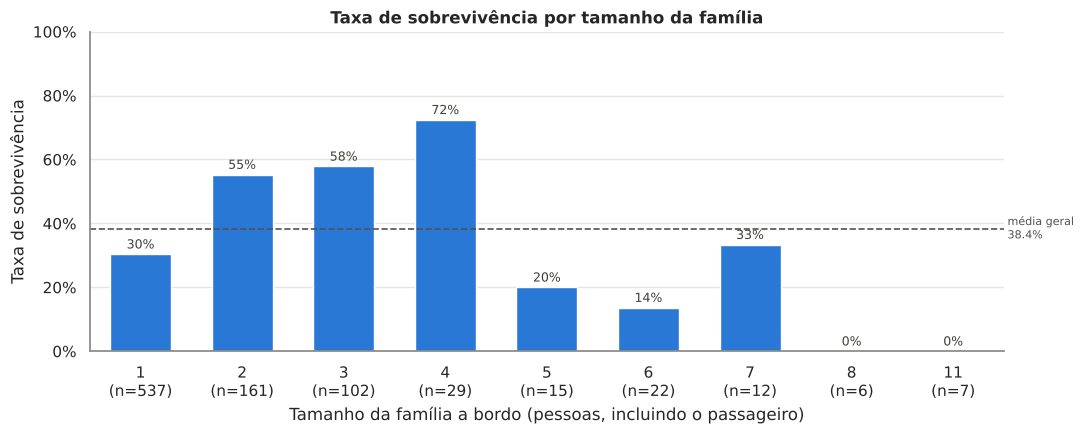

In [24]:
eda["TamanhoFamilia"] = eda["SibSp"] + eda["Parch"] + 1

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=eda, x="TamanhoFamilia", y=alvo, errorbar=None, color=COR_TAXA, saturation=1, width=0.6, ax=ax)
rotular_barras(ax)
n = eda["TamanhoFamilia"].value_counts().sort_index()
ax.set_xticks(range(len(n)), [f"{t}\n(n={n[t]})" for t in n.index])
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Tamanho da família a bordo (pessoas, incluindo o passageiro)")
ax.set_ylabel("Taxa de sobrevivência")
ax.set_title("Taxa de sobrevivência por tamanho da família")
linha_media(ax)
plt.tight_layout()
plt.show()

**Leitura:**
- A relação tem **forma de "U" invertido**: quem viajava **sozinho** (537 pessoas, 60% do total) teve só **30,4%** de sobrevivência. Famílias de **2 a 4 pessoas** ficaram bem acima da média (55% a 72%), e famílias de **5 ou mais** voltaram a ter taxas baixas (0% a 33%).
- Uma explicação plausível: famílias pequenas conseguiam se manter juntas e incluíam mulheres e crianças, que tinham prioridade. Famílias grandes estavam quase todas na 3ª classe (a família Sage, por exemplo, com 7 pessoas no dataset e nenhum sobrevivente).
- **Por isso a correlação de `TamanhoFamilia` com `Survived` é praticamente zero (0,02) no mapa de calor**, apesar de a relação existir: a correlação só mede tendência em linha reta, e aqui a curva sobe e depois desce. Para um modelo, faixas como "sozinho / pequena / grande" capturam essa relação melhor que o número bruto.

#### 6.6 Mapa de calor de correlação

Correlação de Pearson entre as variáveis numéricas e o alvo. Para entrar no cálculo, `Sex` foi convertido em 0/1 (`Sex_male`: 1 = homem) **só nesta cópia**, e a codificação definitiva fica para o Passo 9.

*Como ler:* valores perto de **+1** (azul) indicam que as duas variáveis sobem juntas, perto de **−1** (vermelho) que uma sobe enquanto a outra desce, e perto de **0** (cinza) que não há relação **linear**. Para variáveis binárias (`Survived`, `Sex_male`) e ordinais (`Pclass`), o valor é uma aproximação útil para comparar intensidades, não uma medida exata.

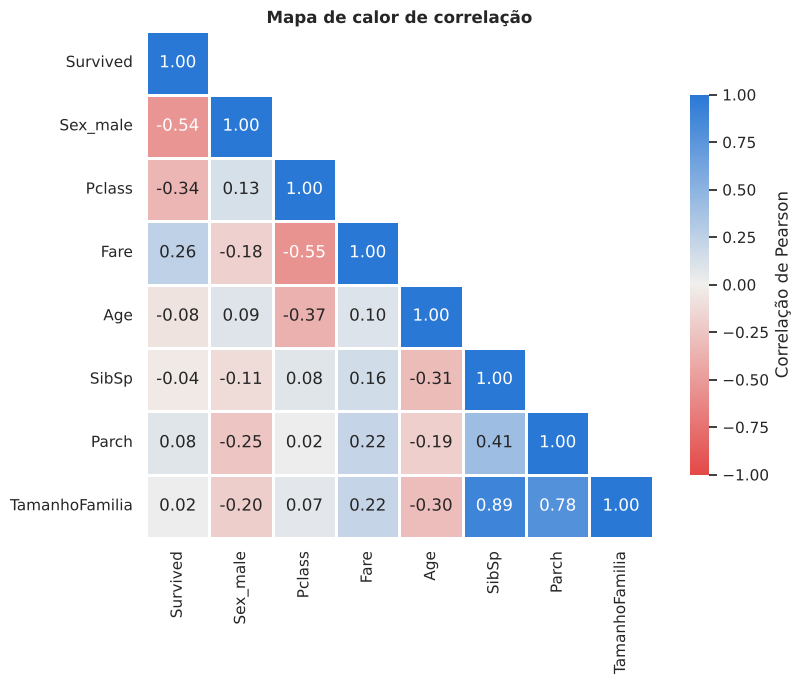

,Correlação com Survived
Sex_male,-0.54
Pclass,-0.34
Fare,0.26
Parch,0.08
Age,-0.08
SibSp,-0.04
TamanhoFamilia,0.02


In [25]:
eda["Sex_male"] = (eda["Sex"] == "male").astype(int)
colunas_corr = ["Survived", "Sex_male", "Pclass", "Fare", "Age", "SibSp", "Parch", "TamanhoFamilia"]
correlacao = eda[colunas_corr].corr()

# Escala divergente: vermelho (negativa) – cinza (zero) – azul (positiva)
cmap_div = LinearSegmentedColormap.from_list("divergente", ["#e34948", "#f0efec", "#2a78d6"])
mascara = np.triu(np.ones_like(correlacao, dtype=bool), k=1)   # mostra só metade (a matriz é espelhada)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlacao, mask=mascara, cmap=cmap_div, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            linewidths=2, linecolor="white", square=True, cbar_kws={"shrink": 0.75, "label": "Correlação de Pearson"}, ax=ax)
ax.set_title("Mapa de calor de correlação")
ax.grid(False)
plt.tight_layout()
plt.show()

# Correlações com o alvo, da mais forte para a mais fraca (em valor absoluto)
correlacao[alvo].drop(alvo).sort_values(key=abs, ascending=False).round(2).to_frame("Correlação com Survived")

**Leitura:**
- **Correlações mais fortes com `Survived`:** `Sex_male` (**−0,54**, ser homem reduz a chance), `Pclass` (**−0,34**, classe com número maior, ou seja pior, reduz a chance) e `Fare` (**+0,26**, tarifa maior aumenta a chance). Isso confirma, em um único número, o que os gráficos dos Passos 5 e 6 mostraram.
- **`Age`, `SibSp`, `Parch` e `TamanhoFamilia` aparecem perto de zero, mas isso não significa "sem relação".** Os Passos 6.4 e 6.5 mostraram relações **não lineares** (crianças priorizadas e famílias em "U" invertido) que a correlação de Pearson não capta. O mapa de calor deve ser lido **junto com os gráficos**, nunca sozinho.
- **Relações entre as explicativas (redundância):**
  - `Pclass` × `Fare` = **−0,55**: as duas medem a mesma coisa (nível socioeconômico). Isso não impede o uso das duas, mas modelos lineares como a regressão logística podem ter coeficientes instáveis quando duas variáveis andam tão juntas.
  - `TamanhoFamilia` × `SibSp` (**0,89**) e × `Parch` (**0,78**): a correlação alta é esperada, porque uma é a soma das outras. No modelo, usar **ou** a variável derivada **ou** as originais, não as três.
  - `Age` × `Pclass` = **−0,37**: passageiros de 1ª classe eram, em média, mais velhos. Isso apoia a ideia de imputar a idade por classe no Bloco C.

### Síntese do Bloco B

| Pergunta | Resposta dos dados | Consequência para os próximos passos |
|---|---|---|
| O alvo é balanceado? | Não: 61,6% não sobreviveram e 38,4% sobreviveram | Usar métricas além da acurácia e divisão estratificada |
| Qual o fator mais forte? | **Sexo** (74,2% contra 18,9%), seguido de **classe** (63% → 24%) | `Sex` e `Pclass` são variáveis centrais e devem ser codificadas corretamente (Passo 9) |
| Os fatores agem sozinhos? | Não: classe pesa muito mais para mulheres, e crianças foram priorizadas independentemente do sexo | Interações importam; o título extraído de `Name` (*Master*, *Miss*…) pode capturar idade e sexo juntos |
| O porto de embarque importa? | Pouco por si só: a vantagem de Cherbourg vem principalmente da composição por classe e sexo | `Embarked` tem papel secundário; preencher os 2 ausentes não é decisão crítica (Passo 7) |
| A idade e a família importam? | Sim, mas de forma **não linear**, por isso aparecem quase em zero no mapa de calor | Avaliar faixas (criança/adulto; sozinho/pequena/grande) em vez dos números brutos |
| Os ausentes de `Age` são aleatórios? | Não: sem idade, a sobrevivência é de 29,4% contra 40,6% | Imputar `Age` por grupo (sexo/classe/título), não pela média geral (Passo 7) |
| Há variáveis redundantes? | `Pclass` × `Fare` (−0,55); `TamanhoFamilia` × `SibSp`/`Parch` | Escolher entre as originais e as derivadas antes de modelar |

## Bloco C — Limpeza dos dados

Este bloco transforma os achados dos Blocos A e B em **decisões de limpeza**: o que fazer com os valores ausentes (Passo 7), com os *outliers* e com as colunas sem uso (Passo 8).

Toda a limpeza é feita numa cópia chamada `dados`. O `df` original continua intacto, o que permite comparar o antes e o depois e refazer qualquer etapa sem baixar o arquivo de novo.

In [26]:
# Cópia de trabalho para a limpeza (df continua sendo o dado bruto)
dados = df.copy()

# Cores dos gráficos deste bloco
COR_DIST = "#52514e"        # distribuições (cinza escuro)
COR_IMPUTADO = "#eda100"    # valores preenchidos na imputação (amarelo)

def tabela_iqr(serie):
    """Limites da regra do IQR e quantidade de outliers de uma coluna."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    fora = (serie < lim_inf) | (serie > lim_sup)
    return pd.Series({"Q1": q1, "Q3": q3, "IQR": iqr, "Limite inferior": lim_inf, "Limite superior": lim_sup,
                      "Outliers": int(fora.sum()), "% outliers": round(fora.mean() * 100, 1),
                      "Assimetria": round(serie.skew(), 2)})

### Passo 7 — Valores ausentes

#### 7.1 Quantificação

In [27]:
ausentes = pd.DataFrame({
    "Ausentes": df.isnull().sum(),
    "% ausentes": (df.isnull().mean() * 100).round(1),
}).sort_values("% ausentes", ascending=False)
ausentes

,Ausentes,% ausentes
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2
PassengerId,0,0.0
Name,0,0.0
Pclass,0,0.0
Survived,0,0.0
Sex,0,0.0
Parch,0,0.0
SibSp,0,0.0


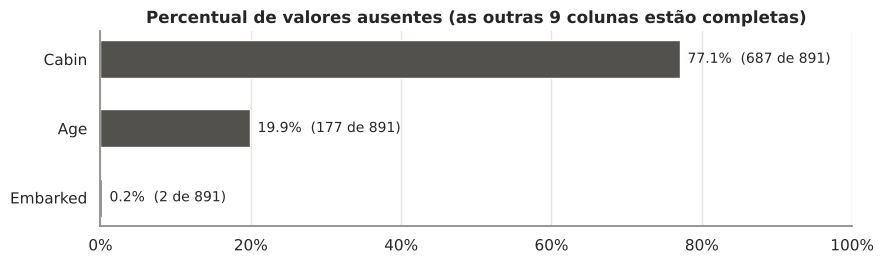

In [28]:
com_ausentes = ausentes[ausentes["Ausentes"] > 0]

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(com_ausentes.index, com_ausentes["% ausentes"] / 100, color=COR_DIST, height=0.55)
for i, (col, linha) in enumerate(com_ausentes.iterrows()):
    ax.text(linha["% ausentes"] / 100 + 0.01, i, f"{linha['% ausentes']:.1f}%  ({int(linha['Ausentes'])} de {len(df)})",
            va="center", fontsize=10)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.invert_yaxis()
ax.set_title("Percentual de valores ausentes (as outras 9 colunas estão completas)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Leitura:** só 3 das 12 colunas têm ausentes, e em **níveis muito diferentes**: `Cabin` está quase toda vazia (77,1%), `Age` tem uma parte relevante faltando (19,9%) e `Embarked` tem só 2 casos (0,2%). Por isso **cada coluna recebe uma estratégia diferente**.

#### 7.2 Estratégia por coluna

| Coluna | Ausentes | Alternativas consideradas | Decisão | Justificativa |
|---|---|---|---|---|
| `Cabin` | 77,1% | Preencher com "Desconhecido"; preencher pela moda; descartar a coluna | **Descartar a coluna** e guardar só a informação `TemCabine` (1 = cabine registrada) | Com 3 de cada 4 valores faltando, qualquer preenchimento seria inventado. Mas o fato de **ter ou não** cabine registrada é informativo (ver 7.3). |
| `Age` | 19,9% | Remover as 177 linhas; média geral; mediana geral; **mediana por grupo** | **Mediana por sexo e classe**, mais uma coluna `IdadeImputada` (1 = idade preenchida) | Remover linhas perderia 20% dos dados. A **mediana** é melhor que a média porque não é puxada pelos idosos. **Por grupo**, porque a idade varia com a classe (correlação −0,37 no mapa de calor). A coluna indicadora guarda o fato de que, sem idade, a sobrevivência era menor (29,4% contra 40,6%, Passo 6.4). |
| `Embarked` | 2 linhas | Remover as 2 linhas; **moda** | **Moda (Southampton)** | Com só 2 casos, o impacto é mínimo, e remover linhas descartaria também os outros dados delas. A moda é o padrão para uma variável nominal (não existe média de porto). |

#### 7.3 `Cabin`: descartar, mas guardar se a cabine foi registrada

In [29]:
dados["TemCabine"] = dados["Cabin"].notna().astype(int)

print("Taxa de sobrevivência por registro de cabine:")
print(dados.groupby("TemCabine")[alvo].agg(["mean", "size"]).rename(index={0: "Sem cabine", 1: "Com cabine"})
      .rename(columns={"mean": "taxa", "size": "passageiros"}).round(3))
print("\n% com cabine registrada em cada classe:")
print((dados.groupby("Pclass")["TemCabine"].mean() * 100).round(1).rename(ROTULOS["Pclass"]))

dados = dados.drop(columns="Cabin")

Taxa de sobrevivência por registro de cabine:
             taxa  passageiros
TemCabine                     
Sem cabine  0.300          687
Com cabine  0.667          204

% com cabine registrada em cada classe:
Pclass
1ª classe    81.5
2ª classe     8.7
3ª classe     2.4
Name: TemCabine, dtype: float64


**Leitura:** quem tem cabine registrada sobreviveu **66,7%**, contra **30,0%** de quem não tem. Mas a cabine foi registrada principalmente na 1ª classe (81,5%, contra 8,7% na 2ª e 2,4% na 3ª), então `TemCabine` carrega **muito da mesma informação de `Pclass`**. Ela é mantida como um complemento simples, e a coluna original `Cabin` é descartada.

#### 7.4 `Embarked`: preencher com a moda

In [30]:
moda_embarked = dados["Embarked"].mode()[0]
print(f"Moda de Embarked: {moda_embarked} ({ROTULOS['Embarked'][moda_embarked]})")
display(dados.loc[dados["Embarked"].isna(), ["Name", "Pclass", "Ticket", "Fare", "Survived"]])

dados["Embarked"] = dados["Embarked"].fillna(moda_embarked)

Moda de Embarked: S (Southampton)


,Name,Pclass,Ticket,Fare,Survived
61,"Icard, Miss. Amelie",1,113572,80.0,1
829,"Stone, Mrs. George Nelson (Martha Evelyn)",1,113572,80.0,1


**Leitura:** as 2 passageiras sem porto (Amelie Icard e Martha Stone) viajavam juntas, no mesmo bilhete de 1ª classe. Elas foram preenchidas com **Southampton**, a moda (72% dos passageiros). Como conferência externa, os registros históricos da Encyclopedia Titanica indicam que as duas **embarcaram de fato em Southampton**, então nesse caso a moda coincide com o valor real.

#### 7.5 `Age`: mediana por sexo e classe

Antes de preencher, comparamos as duas opções mais comuns: a **mediana geral** (um único valor para todos) e a **mediana por grupo** (um valor para cada combinação de sexo e classe).

In [31]:
mediana_por_grupo = dados.groupby(["Sex", "Pclass"])["Age"].median()
display(mediana_por_grupo.unstack().rename(index=ROTULOS["Sex"], columns=ROTULOS["Pclass"]))

idade_original = dados["Age"].copy()
ausente_idade = idade_original.isna()

opcao_geral = idade_original.fillna(idade_original.median())
opcao_grupo = idade_original.fillna(dados.groupby(["Sex", "Pclass"])["Age"].transform("median"))

comparacao_idade = pd.DataFrame({
    "Original (sem ausentes)": idade_original.describe(),
    "Mediana geral": opcao_geral.describe(),
    "Mediana por sexo e classe": opcao_grupo.describe(),
}).T[["count", "mean", "std", "50%"]].round(2)
comparacao_idade

Pclass,1ª classe,2ª classe,3ª classe
Sex,,,
Mulher,35.0,28.0,21.5
Homem,40.0,30.0,25.0


,count,mean,std,50%
Original (sem ausentes),714.0,29.70,14.53,28.0
Mediana geral,891.0,29.36,13.02,28.0
Mediana por sexo e classe,891.0,29.11,13.30,26.0


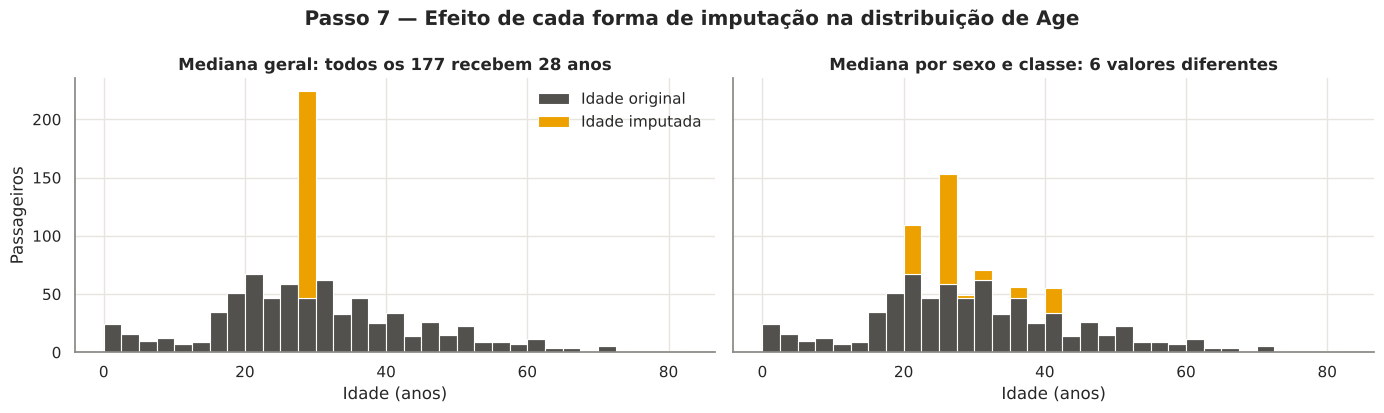

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
faixas = np.arange(0, 85, 2.5)

for ax, serie, titulo in [(axes[0], opcao_geral, "Mediana geral: todos os 177 recebem 28 anos"),
                          (axes[1], opcao_grupo, "Mediana por sexo e classe: 6 valores diferentes")]:
    ax.hist([serie[~ausente_idade], serie[ausente_idade]], bins=faixas, stacked=True,
            color=[COR_DIST, COR_IMPUTADO], label=["Idade original", "Idade imputada"], edgecolor="white", linewidth=0.8)
    ax.set_title(titulo)
    ax.set_xlabel("Idade (anos)")
axes[0].set_ylabel("Passageiros")
axes[0].legend(frameon=False)
fig.suptitle("Passo 7 — Efeito de cada forma de imputação na distribuição de Age", fontweight="bold")
plt.tight_layout()
plt.show()

In [33]:
# Decisão: mediana por sexo e classe + indicador de imputação
dados["IdadeImputada"] = ausente_idade.astype(int)
dados["Age"] = opcao_grupo

print(f"Ausentes restantes em Age: {dados['Age'].isna().sum()}")

Ausentes restantes em Age: 0


**Leitura:**
- As medianas variam bastante entre os grupos: de **21,5 anos** (mulheres de 3ª classe) a **40 anos** (homens de 1ª). Um valor único (28) seria impreciso para quase todos.
- **Mediana geral:** cria um **pico artificial** (de 25 para 202 passageiros com exatamente 28 anos) e reduz o desvio padrão de 14,53 para 13,02. Ou seja, a coluna fica com variação menor do que a real.
- **Mediana por grupo:** espalha os valores imputados em 6 idades diferentes, coerentes com o perfil de cada passageiro. O desvio padrão (13,30) fica mais perto do original.
- **Impacto e limitação:** qualquer imputação "inventa" valores e reduz um pouco a variação. Por isso a coluna `IdadeImputada` registra quais idades foram preenchidas. Uma limitação conhecida: 4 meninos (título *Master*) sem idade recebem a mediana dos homens adultos da sua classe. Usar o **título extraído de `Name`** como grupo seria um refinamento possível.

In [34]:
# Conferência: nenhuma coluna ainda em uso tem ausentes
print("Ausentes após o Passo 7:")
print(dados.isnull().sum()[lambda s: s > 0] if dados.isnull().sum().any() else "nenhum")

Ausentes após o Passo 7:
nenhum


### Passo 8 — *Outliers* e redução do dataset

#### 8.1 Detecção: boxplot + regra do IQR

A regra do IQR considera *outlier* todo valor abaixo de **Q1 − 1,5 × IQR** ou acima de **Q3 + 1,5 × IQR**, onde IQR = Q3 − Q1 (a faixa onde estão os 50% centrais dos dados). Ela foi escolhida em vez do **z-score** (valores a mais de 3 desvios padrão da média) porque usa quartis, que **não são distorcidos pelos próprios outliers**, enquanto o z-score depende da média e do desvio padrão, que são. Isso pesa especialmente em `Fare`, muito assimétrica.

Para `Age`, a detecção usa os **valores originais** (sem os imputados), porque a imputação concentra valores no centro e estreita o IQR artificialmente.

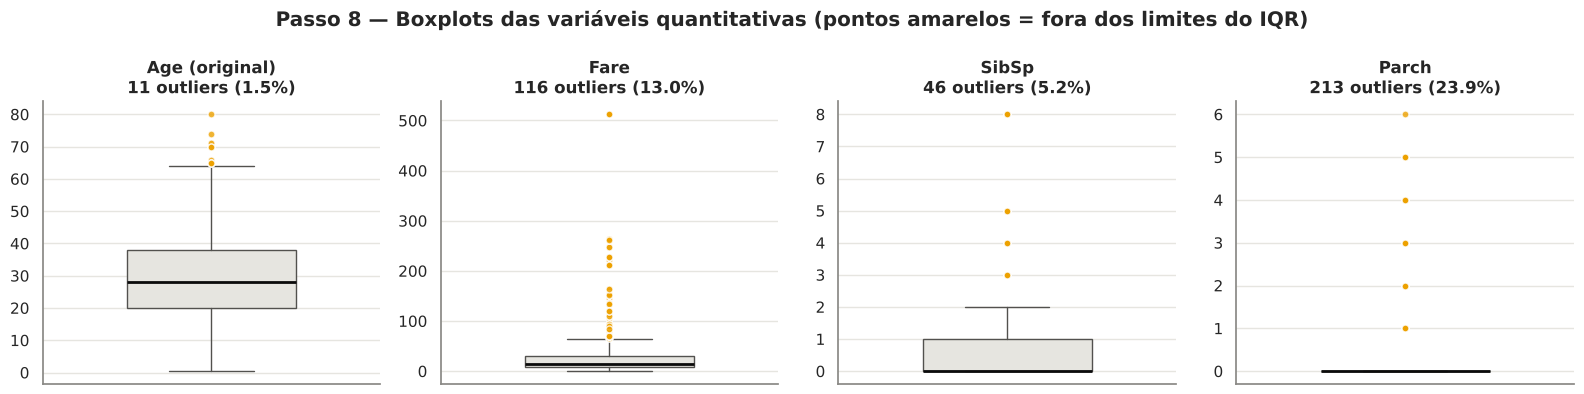

,Q1,Q3,IQR,Limite inferior,Limite superior,Outliers,% outliers,Assimetria
Age (original),20.12,38.0,17.88,-6.69,64.81,11.0,1.5,0.39
Fare,7.91,31.0,23.09,-26.72,65.63,116.0,13.0,4.79
SibSp,0.00,1.0,1.00,-1.50,2.50,46.0,5.2,3.70
Parch,0.00,0.0,0.00,0.00,0.00,213.0,23.9,2.75
Age (após imputação),21.50,36.0,14.50,-0.25,57.75,33.0,3.7,0.53


In [35]:
colunas_outliers = {
    "Age (original)": idade_original.dropna(),
    "Fare": dados["Fare"],
    "SibSp": dados["SibSp"],
    "Parch": dados["Parch"],
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (col, serie) in zip(axes, colunas_outliers.items()):
    ax.boxplot(serie, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor="#e6e5e0", color=COR_DIST), medianprops=dict(color="#0b0b0b", linewidth=2),
               whiskerprops=dict(color=COR_DIST), capprops=dict(color=COR_DIST),
               flierprops=dict(marker="o", markersize=5, markerfacecolor=COR_IMPUTADO, markeredgecolor="white", alpha=0.8))
    n_out = int(tabela_iqr(serie)["Outliers"])
    ax.set_title(f"{col}\n{n_out} outliers ({n_out / len(serie):.1%})")
    ax.set_xticks([])
fig.suptitle("Passo 8 — Boxplots das variáveis quantitativas (pontos amarelos = fora dos limites do IQR)", fontweight="bold")
plt.tight_layout()
plt.show()

tabela_outliers = pd.DataFrame({col: tabela_iqr(s) for col, s in colunas_outliers.items()}).T
tabela_outliers.loc["Age (após imputação)"] = tabela_iqr(dados["Age"])
tabela_outliers.round(2)

#### 8.2 Erro ou valor real? Decisão por coluna

O IQR **aponta** valores incomuns, mas não diz se eles estão errados. Para cada coluna, a pergunta é: o valor é **impossível ou incoerente** (erro, então corrigir ou remover) ou **raro mas real** (manter e, se necessário, reduzir o efeito dele)?

In [36]:
limite_fare = tabela_iqr(dados["Fare"])["Limite superior"]
fare_alto = dados[dados["Fare"] > limite_fare]

# Quantas pessoas usam o mesmo bilhete (recalculado aqui para o bloco ser independente)
pessoas_por_ticket = dados.groupby("Ticket")["Ticket"].transform("size")

print(f"Outliers de Fare (acima de {limite_fare:.2f}): {len(fare_alto)}")
print(f"  por classe: {fare_alto['Pclass'].value_counts().sort_index().rename(ROTULOS['Pclass']).to_dict()}")
print(f"  em bilhetes compartilhados: {(pessoas_por_ticket[fare_alto.index] > 1).mean():.1%}")
print(f"  taxa de sobrevivência: {fare_alto[alvo].mean():.1%} (média geral: {taxa_geral:.1%})")
print(f"\nIdades acima do limite ({tabela_iqr(idade_original.dropna())['Limite superior']:.1f} anos):",
      sorted(idade_original[idade_original > tabela_iqr(idade_original.dropna())["Limite superior"]].tolist()))

Outliers de Fare (acima de 65.63): 116
  por classe: {'1ª classe': 104, '2ª classe': 5, '3ª classe': 7}
  em bilhetes compartilhados: 92.2%
  taxa de sobrevivência: 68.1% (média geral: 38.4%)

Idades acima do limite (64.8 anos): [65.0, 65.0, 65.0, 66.0, 70.0, 70.0, 70.5, 71.0, 71.0, 74.0, 80.0]


**Decisões:**

| Coluna | O que o IQR apontou | Erro ou real? | Decisão |
|---|---|---|---|
| `Age` | 11 idades acima de 64,8 anos (máx. 80) | **Real**: idades plausíveis para adultos idosos, sem nenhum valor impossível | **Manter**. A padronização do Passo 10 já lida com a escala. |
| `Fare` | 116 tarifas acima de 65,63 (13% dos passageiros) | **Real**: 104 são de 1ª classe e 92% estão em bilhetes compartilhados (preço do grupo, Bloco A) | **Manter as linhas**, mas trocar por **tarifa por pessoa** e aplicar **logaritmo** (8.3) |
| `SibSp` | 46 valores (3 ou mais irmãos/cônjuges) | **Real**: famílias grandes, como a Sage | **Manter**, resumido em `TipoFamilia` (8.4) |
| `Parch` | 213 valores (24%): **qualquer valor acima de 0** | **Real**. Aqui a regra falha: como 76% têm `Parch = 0`, Q1 = Q3 = 0 e o IQR é zero | **Manter**, resumido em `TipoFamilia` (8.4) |

**Por que não remover?** Remover os outliers de `Fare` apagaria **13% do dataset**, quase todo da 1ª classe e com **68,1% de sobreviventes**. O dataset ficaria mais "pobre" e com menos sobreviventes do que a realidade, ou seja, **a remoção criaria um viés**. Em `Parch`, a remoção eliminaria todas as pessoas que viajavam com pais ou filhos. A estratégia é **manter as linhas e reduzir o efeito dos valores extremos** com transformações.

#### 8.3 `Fare`: tarifa por pessoa + logaritmo

Duas etapas, cada uma resolvendo um problema:
1. **Tarifa por pessoa** (`Fare` ÷ pessoas no bilhete) corrige o problema encontrado no Bloco A: `Fare` era o preço do bilhete inteiro.
2. **Logaritmo** (`log1p`, ou seja log(1 + x), que aceita as 15 tarifas zero) comprime os valores altos sem eliminá-los. A diferença entre 100 e 200 passa a pesar tanto quanto a diferença entre 10 e 20.

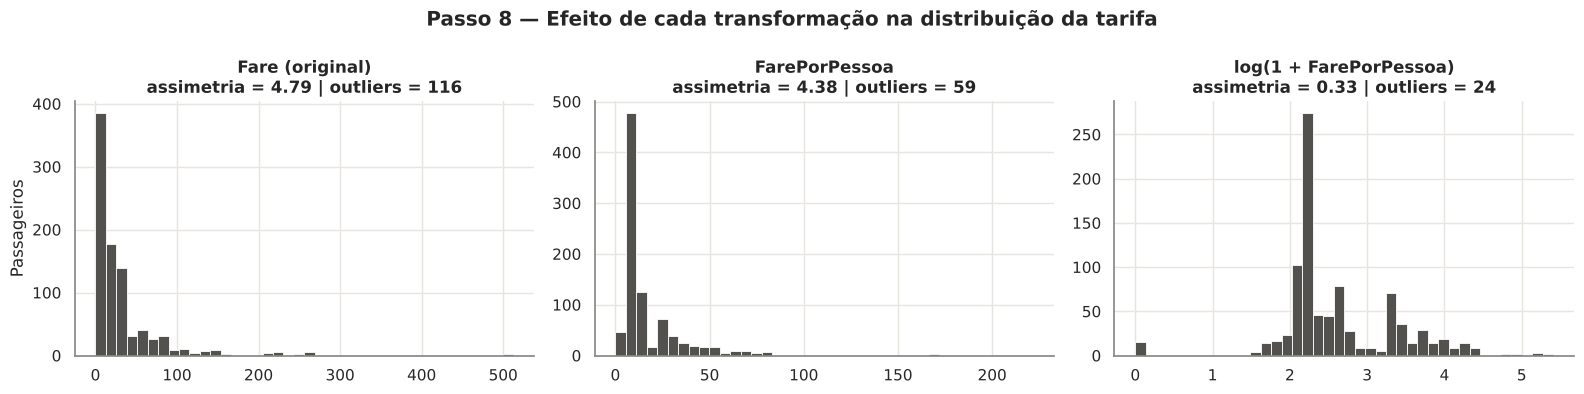

,Limite superior,Outliers,% outliers,Assimetria
Fare (original),65.63,116.0,13.0,4.79
FarePorPessoa,49.08,59.0,6.6,4.38
log(1 + FarePorPessoa),4.82,24.0,2.7,0.33


In [37]:
dados["FarePorPessoa"] = dados["Fare"] / pessoas_por_ticket
dados["FarePorPessoa_log"] = np.log1p(dados["FarePorPessoa"])

versoes_fare = {
    "Fare (original)": dados["Fare"],
    "FarePorPessoa": dados["FarePorPessoa"],
    "log(1 + FarePorPessoa)": dados["FarePorPessoa_log"],
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (nome, serie) in zip(axes, versoes_fare.items()):
    ax.hist(serie, bins=40, color=COR_DIST, edgecolor="white", linewidth=0.6)
    r = tabela_iqr(serie)
    ax.set_title(f"{nome}\nassimetria = {r['Assimetria']:.2f} | outliers = {int(r['Outliers'])}")
    ax.set_ylabel("Passageiros" if nome.startswith("Fare (") else "")
fig.suptitle("Passo 8 — Efeito de cada transformação na distribuição da tarifa", fontweight="bold")
plt.tight_layout()
plt.show()

pd.DataFrame({nome: tabela_iqr(s) for nome, s in versoes_fare.items()}).T[["Limite superior", "Outliers", "% outliers", "Assimetria"]].round(2)

**Leitura:**
- **`Fare` original:** assimetria de **4,79** (fortíssima, à direita) e **116 outliers (13%)**.
- **Tarifa por pessoa:** os outliers caem para **59 (6,6%)**, todos da 1ª classe. Metade dos "outliers" originais era só **efeito de bilhete de grupo**.
- **Depois do logaritmo:** a assimetria cai para **0,33** (distribuição quase simétrica) e restam **24 valores (2,7%)** fora dos limites. Desses, **15 estão no limite inferior**, e são exatamente as 15 tarifas zero (cortesias, Bloco A). Os outros 9 são tarifas individuais de 1ª classe. Todos são valores reais.
- **Decisão:** usar `FarePorPessoa_log` no dataset final. `Fare` e a versão sem log são descartadas. Nenhuma linha foi removida.

#### 8.4 `SibSp` e `Parch` → `TipoFamilia`

No Passo 6.5, a sobrevivência teve forma de "U" invertido em relação ao tamanho da família. Uma variável com 3 faixas captura essa relação melhor que os números brutos e elimina os "outliers" de família grande sem apagar ninguém.

In [38]:
tamanho_familia = dados["SibSp"] + dados["Parch"] + 1
dados["TipoFamilia"] = pd.cut(tamanho_familia, bins=[0, 1, 4, tamanho_familia.max()],
                              labels=["Sozinho", "Pequena", "Grande"]).astype(str)

dados.groupby("TipoFamilia")[alvo].agg(["mean", "size"]).loc[["Sozinho", "Pequena", "Grande"]] \
    .rename(columns={"mean": "Taxa de sobrevivência", "size": "Passageiros"}).round(3)

,Taxa de sobrevivência,Passageiros
TipoFamilia,,
Sozinho,0.304,537
Pequena,0.579,292
Grande,0.161,62


**Leitura:** *Sozinho* (1 pessoa) tem **30,4%** de sobrevivência, *Pequena* (2 a 4) tem **57,9%** e *Grande* (5 ou mais) tem **16,1%**. As três faixas preservam o "U" invertido que o número bruto escondia (correlação de apenas 0,02). Os limites seguem o gráfico do Passo 6.5: a taxa sobe até 4 pessoas e despenca a partir de 5.

#### 8.5 Redução do dataset: colunas removidas

| Coluna removida | Motivo |
|---|---|
| `PassengerId` | Identificador sequencial, sem relação com o desfecho |
| `Name` | Texto único por pessoa (o título poderia ser extraído como melhoria futura) |
| `Ticket` | Código com 681 valores e formato irregular; já foi usado para calcular a tarifa por pessoa |
| `Cabin` | 77% ausente; substituída por `TemCabine` (já removida no Passo 7) |
| `Fare`, `FarePorPessoa` | Substituídas por `FarePorPessoa_log` |
| `SibSp`, `Parch` | Substituídas por `TipoFamilia`, evitando a redundância apontada no mapa de calor |

**Linhas removidas: nenhuma.** Não há duplicatas (Passo 2), os ausentes foram imputados e os outliers são valores reais. As 891 linhas são mantidas.

In [39]:
dados = dados.drop(columns=["PassengerId", "Name", "Ticket", "Fare", "FarePorPessoa", "SibSp", "Parch"])

print(f"Formato após a limpeza: {dados.shape[0]} linhas x {dados.shape[1]} colunas")
print(f"Ausentes: {dados.isnull().sum().sum()}")
dados.head()

Formato após a limpeza: 891 linhas x 9 colunas
Ausentes: 0


,Survived,Pclass,Sex,Age,Embarked,TemCabine,IdadeImputada,FarePorPessoa_log,TipoFamilia
0,0,3,male,22.0,S,0,0,2.110213,Pequena
1,1,1,female,38.0,C,1,0,4.280593,Pequena
2,1,3,female,26.0,S,0,0,2.188856,Sozinho
3,1,1,female,35.0,S,1,0,3.316003,Pequena
4,0,3,male,35.0,S,0,0,2.202765,Sozinho


## Bloco D — Transformação dos dados

Modelos de *Machine Learning* só trabalham com números e são sensíveis à forma como esses números são apresentados. Este bloco converte as categorias em números (Passo 9) e ajusta a escala das variáveis contínuas (Passo 10).

### Passo 9 — Codificação das variáveis categóricas

#### 9.1 Por que não usar Label Encoding nas nominais?

O **Label Encoding** troca cada categoria por um número inteiro (C = 0, Q = 1, S = 2). O problema é que o modelo passa a tratar esses números como **quantidades com ordem e distância**, como se Southampton fosse "maior" que Cherbourg ou como se a distância de C a S fosse o dobro da de C a Q. Veja o efeito:

In [40]:
exemplo_label = pd.DataFrame({"Embarked": ["C", "Q", "S"]})
exemplo_label["Label Encoding"] = exemplo_label["Embarked"].astype("category").cat.codes
exemplo_label["O que o modelo entende"] = ["menor valor", "valor do meio", "maior valor (= 2 × Q)"]
display(exemplo_label)

media_falsa = dados["Embarked"].astype("category").cat.codes.mean()
print(f"'Porto médio' com Label Encoding: {media_falsa:.2f}  <- número sem significado (entre Queenstown e Southampton?)")

,Embarked,Label Encoding,O que o modelo entende
0,C,0,menor valor
1,Q,1,valor do meio
2,S,2,maior valor (= 2 × Q)


'Porto médio' com Label Encoding: 1.54  <- número sem significado (entre Queenstown e Southampton?)


O **One-Hot Encoding** cria **uma coluna 0/1 para cada categoria**, sem nenhuma ordem entre elas: cada porto vira uma pergunta "sim ou não". Por isso ele é a técnica adequada para variáveis **nominais**.

| Critério | Label Encoding | One-Hot Encoding |
|---|---|---|
| Colunas geradas | 1 | 1 por categoria (k − 1 com `drop_first`) |
| Cria ordem falsa? | **Sim**: modelos lineares, KNN e SVM leem 0 < 1 < 2 como quantidade | **Não**: cada categoria é independente |
| Quando usar | Variáveis **ordinais**, ou modelos de árvore (que só fazem cortes e são menos afetados) | Variáveis **nominais**, principalmente em modelos lineares e baseados em distância |
| Desvantagem | Distorce a relação entre as categorias | Muitas colunas quando a variável tem muitas categorias (por isso `Ticket` e `Cabin` não foram codificadas) |

#### 9.2 Decisão por variável

| Variável | Tipo | Codificação | Resultado |
|---|---|---|---|
| `Sex` | Nominal binária | One-Hot com `drop_first` | `Sex_male` (1 = homem, 0 = mulher) |
| `Embarked` | Nominal (3 categorias) | One-Hot com `drop_first` | `Embarked_Q`, `Embarked_S` (Cherbourg é a referência: as duas em 0) |
| `TipoFamilia` | Faixas com efeito **não monotônico** | One-Hot com `drop_first` | `TipoFamilia_Pequena`, `TipoFamilia_Sozinho` (*Grande* é a referência) |
| `Pclass` | **Ordinal** | **Mantida como 1, 2, 3** | A ordem é real (1ª > 2ª > 3ª) e o efeito na sobrevivência é monotônico, então o número já carrega a informação correta |

**Por que `drop_first=True`?** Com 3 portos, basta saber 2 colunas para deduzir a terceira (se não é Q nem S, é C). Manter as 3 cria uma **redundância perfeita** (a "armadilha das variáveis *dummy*"), que atrapalha modelos lineares como a regressão logística. A categoria removida vira a **referência**, e as outras são interpretadas em comparação com ela.

`TipoFamilia` recebe One-Hot mesmo tendo uma ordem de tamanho, porque o efeito na sobrevivência **sobe e depois desce**. Com 0, 1 e 2, um modelo linear suporia um efeito em linha reta.

In [41]:
codificado = pd.get_dummies(dados, columns=["Sex", "Embarked", "TipoFamilia"], drop_first=True, dtype=int)

print("Colunas antes:", list(dados.columns))
print("Colunas depois:", list(codificado.columns))
codificado.head()

Colunas antes: ['Survived', 'Pclass', 'Sex', 'Age', 'Embarked', 'TemCabine', 'IdadeImputada', 'FarePorPessoa_log', 'TipoFamilia']
Colunas depois: ['Survived', 'Pclass', 'Age', 'TemCabine', 'IdadeImputada', 'FarePorPessoa_log', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'TipoFamilia_Pequena', 'TipoFamilia_Sozinho']


,Survived,Pclass,Age,TemCabine,IdadeImputada,FarePorPessoa_log,Sex_male,Embarked_Q,Embarked_S,TipoFamilia_Pequena,TipoFamilia_Sozinho
0,0,3,22.0,0,0,2.110213,1,0,1,1,0
1,1,1,38.0,1,0,4.280593,0,0,0,1,0
2,1,3,26.0,0,0,2.188856,0,0,1,0,1
3,1,1,35.0,1,0,3.316003,0,0,1,1,0
4,0,3,35.0,0,0,2.202765,1,0,1,0,1


### Passo 10 — Normalização ou padronização

#### 10.1 Quais variáveis precisam?

Só as **contínuas**: `Age` (de 0,42 a 80) e `FarePorPessoa_log` (de 0 a cerca de 5,4). As colunas 0/1 do One-Hot e dos indicadores já estão numa escala comum. `Pclass` (1 a 3) é ordinal e tem amplitude pequena, então foi mantida como está.

#### 10.2 Normalização (Min-Max) ou padronização (Z-score)?

- **Normalização (Min-Max):** (x − mín) ÷ (máx − mín). Coloca tudo entre 0 e 1. Depende do **mínimo e do máximo**, então **um único valor extremo comprime todos os outros**.
- **Padronização (Z-score):** (x − média) ÷ desvio padrão. Deixa média 0 e desvio 1. É **menos sensível a extremos** e é o padrão para regressão logística, SVM e redes neurais.

Para ver a diferença na prática, a comparação abaixo usa a tarifa por pessoa **antes** do logaritmo:

In [42]:
fare_pp = df["Fare"] / pessoas_por_ticket
minmax_sem_log = (fare_pp - fare_pp.min()) / (fare_pp.max() - fare_pp.min())

print(f"Min-Max na tarifa por pessoa SEM log: mediana = {minmax_sem_log.median():.3f} | "
      f"75% dos passageiros abaixo de {minmax_sem_log.quantile(0.75):.3f}")
print("-> o maior valor (221,78) ocupa a ponta da escala e espreme quase todos perto de 0.")

Min-Max na tarifa por pessoa SEM log: mediana = 0.040 | 75% dos passageiros abaixo de 0.110
-> o maior valor (221,78) ocupa a ponta da escala e espreme quase todos perto de 0.


**Decisão: padronização (Z-score) em `Age` e `FarePorPessoa_log`.** Os dois motivos:
1. Os *outliers* foram **mantidos** de propósito (Passo 8). Com Min-Max, eles definiriam o máximo e comprimiriam o resto, como mostrado acima: 75% dos passageiros ficariam espremidos entre 0 e 0,11.
2. Com o log, a tarifa ficou quase simétrica (assimetria 0,33), e a idade também é pouco assimétrica (0,53). Nesse cenário, média e desvio padrão descrevem bem as duas variáveis, que é a premissa do Z-score.

O cálculo é feito com pandas, e o resultado é o mesmo do `StandardScaler` do scikit-learn.

In [43]:
colunas_continuas = ["Age", "FarePorPessoa_log"]
dataset_final = codificado.copy()

medias = dataset_final[colunas_continuas].mean()
desvios = dataset_final[colunas_continuas].std(ddof=0)   # ddof=0: mesmo cálculo do StandardScaler
dataset_final[colunas_continuas] = (dataset_final[colunas_continuas] - medias) / desvios

pd.DataFrame({
    "Média antes": medias, "Desvio antes": desvios,
    "Média depois": dataset_final[colunas_continuas].mean(), "Desvio depois": dataset_final[colunas_continuas].std(ddof=0),
}).round(3) + 0.0   # "+ 0.0" só evita exibir "-0.0"

,Média antes,Desvio antes,Média depois,Desvio depois
Age,29.112,13.297,0.0,1.0
FarePorPessoa_log,2.600,0.764,0.0,1.0


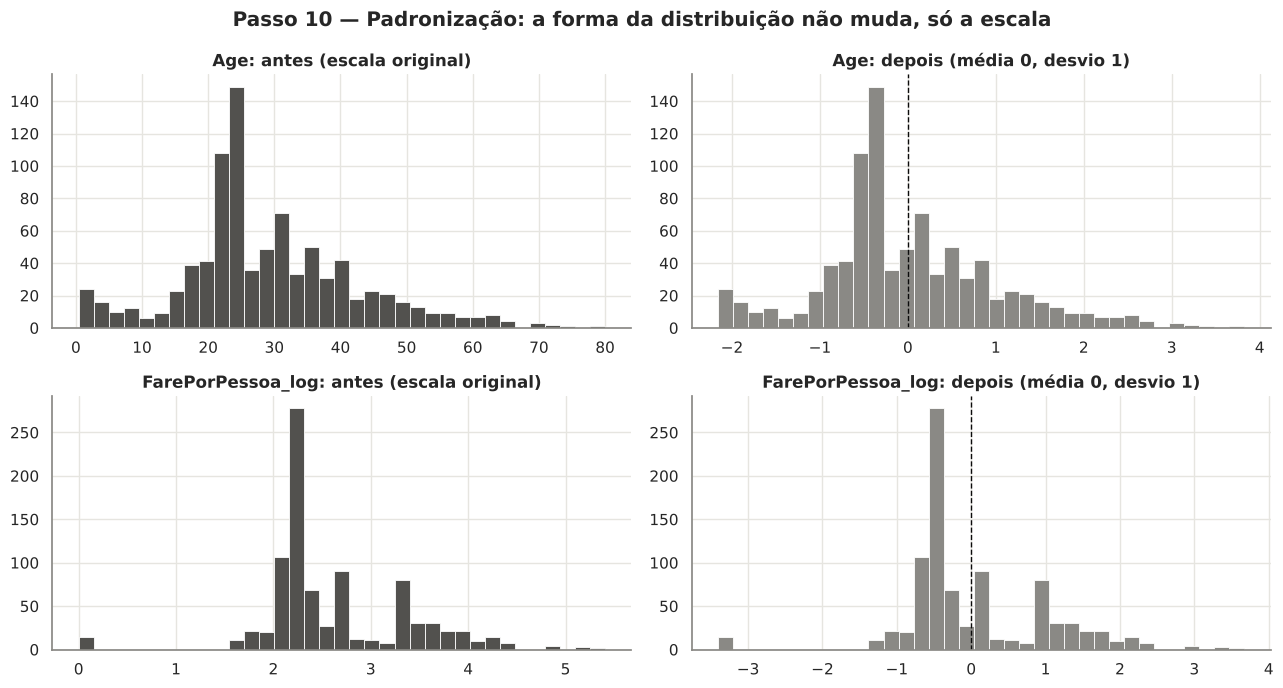

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for linha, col in enumerate(colunas_continuas):
    axes[linha, 0].hist(codificado[col], bins=35, color=COR_DIST, edgecolor="white", linewidth=0.6)
    axes[linha, 0].set_title(f"{col}: antes (escala original)")
    axes[linha, 1].hist(dataset_final[col], bins=35, color="#8a8985", edgecolor="white", linewidth=0.6)
    axes[linha, 1].axvline(0, ls="--", color="#0b0b0b", lw=1)
    axes[linha, 1].set_title(f"{col}: depois (média 0, desvio 1)")
fig.suptitle("Passo 10 — Padronização: a forma da distribuição não muda, só a escala", fontweight="bold")
plt.tight_layout()
plt.show()

**Leitura e impacto em futuros modelos:**
- O gráfico mostra que a padronização **não muda a forma** da distribuição. Ela só desloca o centro para 0 e deixa as duas variáveis na mesma unidade ("quantos desvios padrão acima ou abaixo da média"). Antes, a idade ia até 80 e a tarifa em log até cerca de 5,4. Agora as duas são diretamente comparáveis.
- **Onde isso importa:**
  - **KNN e K-Means** calculam distâncias. Sem padronização, a idade, com números maiores, dominaria a distância.
  - **SVM e regressão logística com regularização** penalizam os coeficientes. Variáveis em escalas diferentes seriam penalizadas de forma desigual.
  - **Redes neurais** e modelos treinados por gradiente convergem mais rápido e de forma mais estável.
- **Onde não importa:** **árvores de decisão, Random Forest e Gradient Boosting** fazem cortes do tipo "idade < 15?". Mudar a escala muda o valor do corte, mas não a ordem dos passageiros, então o resultado é o mesmo.
- **Cuidado para a etapa de modelagem (vazamento de dados):** aqui a média e o desvio foram calculados no dataset inteiro, como pede o exercício. Ao treinar um modelo, eles devem ser calculados **só no conjunto de treino** e depois aplicados ao teste (`StandardScaler().fit(X_treino)`). Senão, informação do teste "vaza" para o treino. O mesmo vale para as medianas da imputação de `Age`.

### Dataset final consolidado

In [45]:
print(f"Formato final: {dataset_final.shape[0]} linhas x {dataset_final.shape[1]} colunas")
print(f"Valores ausentes: {dataset_final.isnull().sum().sum()}")
print(f"Colunas não numéricas: {list(dataset_final.select_dtypes(exclude='number').columns) or 'nenhuma'}")
print(f"Linhas duplicadas: {dataset_final.duplicated().sum()}")
print()
dataset_final.info()

Formato final: 891 linhas x 11 colunas
Valores ausentes: 0
Colunas não numéricas: nenhuma
Linhas duplicadas: 108

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Survived             891 non-null    int64  
 1   Pclass               891 non-null    int64  
 2   Age                  891 non-null    float64
 3   TemCabine            891 non-null    int64  
 4   IdadeImputada        891 non-null    int64  
 5   FarePorPessoa_log    891 non-null    float64
 6   Sex_male             891 non-null    int64  
 7   Embarked_Q           891 non-null    int64  
 8   Embarked_S           891 non-null    int64  
 9   TipoFamilia_Pequena  891 non-null    int64  
 10  TipoFamilia_Sozinho  891 non-null    int64  
dtypes: float64(2), int64(9)
memory usage: 76.7 KB


In [46]:
dataset_final.head()

,Survived,Pclass,Age,TemCabine,IdadeImputada,FarePorPessoa_log,Sex_male,Embarked_Q,Embarked_S,TipoFamilia_Pequena,TipoFamilia_Sozinho
0,0,3,-0.534891,0,0,-0.641064,1,0,1,1,0
1,1,1,0.668392,1,0,2.200411,0,0,0,1,0
2,1,3,-0.234070,0,0,-0.538104,0,0,1,0,1
3,1,1,0.442776,1,0,0.937563,0,0,1,1,0
4,0,3,0.442776,0,0,-0.519895,1,0,1,0,1


In [47]:
dataset_final.to_csv("titanic_processado.csv", index=False)
print("Arquivo salvo: titanic_processado.csv")

Arquivo salvo: titanic_processado.csv


**Estrutura final (891 linhas × 11 colunas, todas numéricas, sem ausentes):**

| Coluna | Origem | Transformação | Escala |
|---|---|---|---|
| `Survived` | Original | Nenhuma (variável alvo) | 0/1 |
| `Pclass` | Original | Mantida como ordinal | 1, 2, 3 |
| `Age` | Original | Imputação pela mediana por sexo e classe → padronização | Z-score |
| `TemCabine` | Derivada de `Cabin` | 1 = cabine registrada | 0/1 |
| `IdadeImputada` | Derivada de `Age` | 1 = idade preenchida no Passo 7 | 0/1 |
| `FarePorPessoa_log` | Derivada de `Fare` e `Ticket` | Tarifa ÷ pessoas no bilhete → log(1 + x) → padronização | Z-score |
| `Sex_male` | `Sex` | One-Hot (referência: mulher) | 0/1 |
| `Embarked_Q`, `Embarked_S` | `Embarked` | Moda nos 2 ausentes → One-Hot (referência: Cherbourg) | 0/1 |
| `TipoFamilia_Pequena`, `TipoFamilia_Sozinho` | `SibSp` + `Parch` | Faixas de tamanho → One-Hot (referência: Grande) | 0/1 |

**Sobre as "duplicatas" do dataset final:** a checagem acima encontra 108 linhas repetidas. Elas **não são registros duplicados**: são passageiros diferentes que, depois da remoção de `Name`, `Ticket` e `PassengerId`, ficaram com o **mesmo perfil** (por exemplo, homens de 3ª classe, sozinhos, com a idade imputada de 25 anos e a mesma tarifa). No dado bruto não havia nenhuma duplicata (Passo 2), então as linhas são **mantidas**. Removê-las apagaria pessoas reais e mudaria as proporções do dataset.

**Pronto para análise preditiva:** todas as colunas são numéricas, não há ausentes, as categorias nominais estão codificadas sem ordem falsa e as contínuas estão na mesma escala. O alvo `Survived` está separado das explicativas (`X = dataset_final.drop(columns="Survived")`, `y = dataset_final["Survived"]`). Na modelagem, lembrar de: (1) divisão treino/teste **estratificada** por causa do desbalanceamento (Passo 4); (2) ajustar imputação e padronização **só no treino**; (3) avaliar com precisão, *recall* e F1, comparando com o piso de **61,6%** de acurácia.

## Conclusão

1. **Sexo e classe foram os fatores decisivos** para a sobrevivência: 74,2% das mulheres contra 18,9% dos homens, e 63,0% na 1ª classe contra 24,2% na 3ª. Os dois efeitos interagem, e a classe pesou muito mais entre as mulheres.
2. **Idade e família têm efeitos não lineares**: crianças foram priorizadas independentemente do sexo, e famílias pequenas sobreviveram mais que pessoas sozinhas ou famílias grandes. Esses efeitos ficam invisíveis no mapa de calor e só aparecem nos gráficos.
3. **O porto de embarque é, em grande parte, uma variável de confusão**: a vantagem de Cherbourg vem da composição de classe e sexo dos seus passageiros.
4. **Na limpeza, nenhuma linha foi removida.** Os ausentes receberam estratégias diferentes conforme o volume e o tipo, e os *outliers*, por serem reais, foram tratados com transformações (tarifa por pessoa e logaritmo) em vez de exclusão.
5. **O dataset final** tem 891 linhas e 11 colunas numéricas, codificadas e padronizadas, pronto para modelos de classificação.